# MAS-QA-SDN: reproduction notebook for the article

**Simulated Quantum Annealing versus Simulated Annealing for SDN Flow Admission under Matched Compute: A Controlled Study**

This notebook reproduces the analysis, tables and figures of the article from the archived data in `data/`. The narrative below is the article text (Abstract to References), and each figure and computed table is placed next to the paragraph that discusses it.

- Figures are generated from `data/` by `code/figures_main.py` (Figures 1–8 and 10 as in the article, with Figure 6 being the iteration plot) and `code/figures_extra.py` (Figures 9, 11, 12, 13). Statistics are in `code/analysis.py`.
- Simulation runs are not repeated here. They take hours. The exact small-instance reference (`code/small_instances.py`) is also not repeated. Its output is in `data/small_v2_all.csv`.
- Bracketed placeholders in the front matter and Declarations (author names, affiliations, repository DOI, funding, and similar) are to be completed before publication.

Figure numbering follows the article. Table 1 and Table 10 are qualitative and are shown as text.

## How to run this notebook

This notebook is part of the reproduction package for the article. It works from the repository layout (`notebooks/`, `code/`, `data/`, `figures/`).

1. Clone the repository, or unzip the Zenodo archive: `git clone https://github.com/[PLACEHOLDER: GitHub user]/MAS-QA-SDN.git`
2. Install the dependencies: `pip install -r requirements.txt`
3. Open this notebook from the `notebooks/` folder (Jupyter, VS Code, or Colab after uploading the repository) and run all cells. The notebook reads the archived data in `data/` and writes the figures to `figures/`; it does not rerun the optimisation experiments, which take substantial CPU time (see the README).

Cells that display a figure show the same image as `figures/`. The reproducibility checks at the end print `OK` when the recomputed values match the values reported in the article.

In [1]:
import os, sys, runpy
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath(os.getcwd())
os.environ['MASQA_ROOT'] = ROOT
sys.path.insert(0, os.path.join(ROOT, 'code'))
import analysis as A
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
runpy.run_path(os.path.join(ROOT, 'code', 'figures_main.py'))
import figures_extra as FX
m = A.load_main(); sc = A.load_scale(); sm = A.load_small(); ea = A.load_earlier()
FX.fig09(m); FX.fig11(sm); FX.fig12(m); FX.fig13(m, sc, ea)
print('data rows: main', len(m), '| scale', len(sc), '| small', len(sm), '| earlier protocol', len(ea))
print('figures in', A.FIG, sorted(os.listdir(A.FIG))[:4], '...')

main figures written to <PACKAGE_ROOT>/figures/


data rows: main 720 | scale 495 | small 560 | earlier protocol 1170
figures in <PACKAGE_ROOT>/figures ['fig01_pipeline.pdf', 'fig01_pipeline.png', 'fig02_topology.pdf', 'fig02_topology.png'] ...


Simulated Quantum Annealing versus Simulated Annealing for SDN Flow Admission under Matched Compute: A Controlled Study

[Author names and affiliations to be inserted]
[Corresponding author e-mail to be inserted]

Manuscript prepared for submission to the International Journal of Intelligent Engineering and Systems (IJIES, INASS).

## Abstract

Quantum-inspired solvers are proposed for network load balancing, but comparisons with classical solvers often differ in tuning, compute budget and the feasibility repair applied after the solver. We study flow admission and path selection on a k = 4 Fat-Tree (16 hosts, 96 directed arcs of 50 Mbps), formulated as a quadratic unconstrained binary optimization (QUBO) problem with binary capacity slack and balance, latency, bandwidth and served-bandwidth fairness terms. We compare simulated quantum annealing (SQA, OpenJij) with simulated annealing (SA) under matched sweep budgets for the monolithic solvers. Both solvers are tuned on validation seeds disjoint from the evaluation seeds, and every solver output is scored after the same priority-ordered repair. Across three main scenarios (50, 100 and 150 flows; 30 seeds each) and a scale study up to 300 flows with constant per-flow demand (24–25 seeds per size), tuned SQA loses 1.6 to 3.1 percentage points (pp) fewer flows than tuned SA at 100 or more flows; at 50 flows the difference is not significant. A pod-decomposed SQA pipeline reaches the flow loss of monolithic SQA within 0.6 pp (not significant) at the tuned budget, while using about one-sixth of its annealing work. At equal annealing work with the initial solver settings, however, the monolithic solver is better by 2.1 pp at 50 flows. Repair is essential: unrepaired solver outputs lose 53–96% of flows. Given repair, the solver adds 3.5–8.4 pp over a greedy coordinator without a solver, and the pipeline reduces lost flows by 4.5–8.2 pp relative to ECMP with capacity-aware admission. Iterating the pod solves with background loads gives no significant gain. The evidence is limited to this model, to surrogate metrics without emulation, and to two solvers with small tuning grids.

Keywords: software-defined networking; load balancing; QUBO; simulated quantum annealing; simulated annealing; Fat-Tree; controlled evaluation.

## 1. Introduction

Data-center networks offer many equal-cost paths between any pair of hosts, yet the forwarding rule used by most deployments, equal-cost multi-path (ECMP) hashing [1], does not look at link capacity. Two flows that hash onto the same link compete for it regardless of how loaded that link already is. In a Fat-Tree fabric [2] built from commodity switches, this produces persistent hot spots: a few links carry most of the traffic while others stay lightly used, and any flow that crosses an overloaded link is lost. Software-defined networking (SDN) [3,4] makes a remedy possible, because a central controller sees link loads and can assign flows to paths. Flow-scheduling systems such as Hedera [5] use this global view to re-place large flows. The underlying decision is still combinatorial: which flows to admit, and on which path, so that no link exceeds its capacity and the admitted traffic is as large as possible.

This decision is a constrained combinatorial optimization problem. Exact solution is intractable in general, and practical controllers rely on heuristics such as greedy placement. One alternative is to encode the problem as a quadratic unconstrained binary optimization (QUBO) model [6,7] and solve it with an annealer. Quantum annealing [8] and its classical simulation, simulated quantum annealing (SQA) [9], are candidate solvers for this class of model, and simulated annealing (SA) [10] is the classical counterpart. Hard capacity constraints must be enforced through penalty terms or binary slack variables. If the penalty weights are too small, violating a constraint can lower the energy, so the solver may return infeasible assignments [6,7]; if they are too large, they overwhelm the objective and make solutions of different quality hard to distinguish [6]. Either way, the solver output usually has to be repaired before it can be scored.

Studies that propose quantum-inspired solvers for network load balancing are not always designed to separate the effect of the solver from the effect of everything around it. Four factors recur. First, the classical baseline is sometimes untuned, so a reported gap may reflect the baseline rather than the solver. Second, the admission rule differs between compared methods, so two methods may admit different sets of flows and their loss figures are not directly comparable. Third, compute budgets are seldom matched: one solver may receive many more annealing sweeps than the other. Fourth, the feasibility repair that turns a solver output into a valid assignment can account for much of the final result. Our own runs illustrate the last two points. At the loads studied here, unrepaired solver outputs lose 53–96% of flows, and the default SA schedule is 0.3 to 2.0 percentage points (pp) worse than a tuned one.

Under these conditions, it is unclear whether a difference between SQA and SA reflects the solvers, the QUBO formulation or the surrounding pipeline. The answer matters for SDN designers, because it decides whether investment in quantum-inspired control is justified over a well-tuned classical heuristic. Section 2 shows that few studies hold the admission rule, the repair, the compute budget and the tuning fixed for both solvers at once.

This paper addresses that question for one well-specified pipeline. We model admission and path selection on a k = 4 Fat-Tree with 16 hosts and 96 directed arcs of 50 Mbps. Traffic follows a heavy-tailed Pareto distribution and is split into three service classes (EF, AF and BE). The QUBO combines binary slack for hard capacity with balance, latency, bandwidth and served-bandwidth fairness terms (Section 3.3). Both solvers receive the same model, the same priority-ordered repair and the same admission rule. Their sweep budgets are matched, and both solvers are tuned on validation seeds disjoint from the evaluation seeds (Section 3.5). Results are reported as paired differences over seeds, so each comparison uses identical traffic and background (Section 3.8).

We ask four research questions:

RQ1. Under matched sweep budgets, identical admission rules and tuned settings for both solvers, does SQA lose fewer flows than SA?

RQ2. How much of the result depends on the feasibility repair, on decomposition by pod, and on iterating the decomposition with background loads?

RQ3. How close are the heuristics to the exact optimum of the same model on instances small enough to solve exactly?

RQ4. Do the conclusions hold as the number of flows grows, when per-flow demand is held constant?

The answers are conditional, and we report them that way. A null or negative result is informative for SDN design, because it shows which part of a reported gain comes from the solver and which from the pipeline.

The contributions are as follows. (i) A QUBO for flow admission and path selection, with binary slack for hard capacity and a served-bandwidth fairness term (Section 3.3). (ii) A controlled SQA-versus-SA comparison with matched sweep budgets, validation-selected settings for both solvers, and a sensitivity analysis of the SA schedule (Sections 3.5 and 4.2). (iii) An accounting of what pod decomposition buys and costs. An equal-work control shows that, at equal annealing work with the initial solver settings, the monolithic solver is better, and iterating the decomposition gives no significant gain (Section 4.2). (iv) Ablations that separate the effect of repair from the effect of the solver choice (Section 4.3). (v) An exact reference on small instances and a scale study with constant per-flow demand (Sections 4.5 and 4.6).

The study does not propose a multi-agent architecture, a new routing principle or a sub-second control loop. It uses surrogate metrics without packet-level emulation, and both solvers run as simulations on a classical machine rather than on quantum hardware. Its conclusions are limited to this model, this topology and two solvers with small tuning grids.

Section 2 reviews related work and positions the study against it (Table 1). Section 3 describes the model, the solvers and the protocol. Section 4 reports the results, and Section 5 concludes.

## 2. Related Work

### 2.1 Load balancing in data-center and SDN fabrics

Load balancing in multi-rooted data-center fabrics operates at two levels. The forwarding level decides which path a flow takes, and the admission level decides whether a flow is accepted at all. The two levels are often treated as one, but a path rule that ignores admission can place a flow on a saturated path, where the flow is lost. Equal-cost multi-path (ECMP) forwarding is the default at the forwarding level: it hashes packet or flow headers onto equal-cost paths [1]. It is stateless and fast, but it does not observe link capacity. Skewed traffic can therefore place several large flows on the same link, and the hot spot persists while the hash assignment stays fixed [1,2].

SDN makes a capacity-aware alternative possible. A central controller holds a global view of link loads and can install flow rules accordingly [3,4]. Hedera [5] follows this approach: it estimates the demand of each flow, identifies large flows, and places them on less-loaded paths. Hedera places every large flow it detects and does not refuse flows: when no path has room, the flow falls back to its hashed path [5]. It therefore does not address which flows to refuse when the fabric is saturated.

Our capacity-aware baseline, ECMP+adm, is the simplest version of this idea. It keeps the hashed path and admits a flow only if that path has residual capacity, so the comparison with the optimizers isolates placement quality from admission. Hedera itself is not re-implemented here. Reproducing its demand estimation and placement under the protocol of Section 3.8 would be a separate study.

### 2.2 Learning-based and quantum-inspired approaches

Recent work applies learning and quantum-inspired methods to neighbouring control problems, but in settings that differ from ours. Deep reinforcement learning has been used to balance load across several SDN controllers by migrating switches between them [14]. That work addresses controller load rather than flow admission, and it is evaluated in simulation under its own settings. Its baselines are not described here, because we did not verify them against the full text. Quantum annealing has been applied to an integer linear program for energy-aware resource allocation in optical wide-area networks. The program is reformulated as a QUBO and solved on a D-Wave annealer, and the study examines how annealing time, penalty factor and chain strength relate to solution quality [15]. Its classical reference is an exact CPLEX solution for a three-node instance, not a heuristic run under a matched budget, and D-Wave found no feasible solution for that instance in more than 600,000 samples [15].

Several IJIES papers from 2026 address neighbouring problems: routing and congestion control in next-generation wireless networks [16], trust-aware routing in mobile ad hoc networks [17], spectrum defragmentation in elastic optical networks [18], renewable-aware resource and power optimization in ORAN [19], and interference-aware resource allocation in UAV-assisted VANETs [20]. These works differ from ours in topology, problem and evaluation, and we do not present their reported numbers as benchmarks.

Across these works, the reported gains depend on settings that differ from ours: the topology, the traffic model, the baselines, and the compute given to each method. Without a matched protocol, a reported gain cannot be attributed to the solver alone. Reproducing the quantum-annealing formulation of [15] under the protocol of Section 3.8 is listed as future work. We did not verify whether the baselines in these works were tuned, and we do not claim that they were not.

### 2.3 QUBO formulations and annealing solvers

Many combinatorial network problems can be written as QUBO models [6,7]. Assignment and packing constraints are enforced by penalty terms [6,7]. The penalty weights must make a constraint violation costlier than any gain in the objective. If they are too small, violating a constraint can lower the energy, so the solver may return infeasible assignments [6,7]. If they are too large, they overwhelm the objective and make solutions of different quality hard to distinguish [6]. The solver therefore does not guarantee feasibility, and a repair step is needed before solutions can be compared.

Quantum annealing minimizes a QUBO by evolving a transverse field toward the problem Hamiltonian [8]. Simulated quantum annealing (SQA) is a classical simulation of this dynamics by path-integral Monte Carlo [9], and it is the solver used for the quantum-inspired side of this study. Simulated annealing (SA) [10] is the classical counterpart on the same QUBO. Its schedule is a known source of sensitivity, so we tune it explicitly rather than rely on a default, and Section 4.8 reports how much the default schedule differs from the tuned one. Hardware benchmarks of quantum annealing against SA show that minor embedding and parameter choice can change the outcome substantially, and that the comparison does not define an equal-compute protocol [28]. A QUBO for network throughput has been solved on a digital annealer, a quantum-inspired hardware solver, and the effect of its penalty coefficients is analysed [29]; the abstract does not name a classical baseline.

Heuristic and metaheuristic methods are also widely used for combinatorial routing and scheduling problems. Recent IJIES papers apply hybrid metaheuristics to cloud task scheduling [21] and to capacitated vehicle routing [22]. These methods are not benchmarks here. They show that classical heuristics are a common reference point for problems of this type, which is why the comparison in this study uses SA and a greedy coordinator.

### 2.4 Fairness and evaluation metrics

Fairness across loads is measured with Jain's index [23], which equals one when all loads are equal and decreases as they diverge. For a fixed load vector, JFI = 1/(1 + CoV²), where CoV is the population coefficient of variation. We use this identity as a consistency check on the reported values. Paired comparisons use the paired t-test, and for the headline comparisons the exact Wilcoxon signed-rank test [24] is reported alongside it (Table 4). Multiple comparisons are adjusted with the Bonferroni correction [25]. The exact small-instance reference is solved with the MILP solver HiGHS through SciPy [26].

### 2.5 Gap addressed

The works reviewed above differ in problem, topology, traffic and evaluation, so their reported numbers cannot be combined into a single comparison. Four factors can each account for a difference between two solvers without the solver itself being responsible: the strength of the classical baseline, the admission rule that determines which flows are counted, the compute budget given to each method, and the feasibility repair applied to solver outputs. None of the works reviewed holds all four factors fixed for both solvers at once, as far as the settings we could check show. This study does so for one QUBO formulation of SDN flow admission, with matched sweep budgets and with validation-selected settings for each solver. Within this setting, it asks whether tuned SQA loses fewer flows than tuned SA, and how much of any difference depends on repair and decomposition.

### 2.6 Position relative to representative prior work

Table 1 places this study against the representative prior work in Sections 2.1 to 2.3 and the IJIES entries [11–13, 16–22]. Prior work is either background or uses different settings, so its reported numbers are not directly comparable with ours. The IJIES entries are cited for topic context; their methods were not re-implemented.

Table 1. Position of this study relative to representative prior work.

**Table 1.** Position of this study relative to representative prior work.

| Work (ref.) | Problem and setting | Method | Comparison in this study | Position of this study |
|---|---|---|---|---|
| Hedera, Al-Fares et al. [5] | Dynamic flow scheduling in data-center fabrics; large flows re-placed to reduce hot spots. | Central scheduler; max-min fair demand estimation; flows above 100 Mbps placed by Global First Fit; otherwise the hashed path is kept. | Not re-implemented. The capacity-aware ECMP+adm baseline is the closest comparator. | Shares the goal of capacity-aware placement. Differs in scope: this study fixes the admission rule and compares solvers on one QUBO. |
| ECMP, Hopps [1] | Equal-cost multi-path forwarding by header hashing; not capacity-aware. | Stateless hashing. | Used directly as the ECMP baseline and, with admission, as ECMP+adm. | Provides the reference floor. The gap between ECMP+adm and MAS-QA is 6.9–7.7 pp in the main scenarios. |
| Fat-Tree, Al-Fares et al. [2] | Data-center topology with many equal-cost paths. | Topology definition (k = 4 in this study). | Same topology used in all scenarios. | Setting only. No claim beyond this topology. |
| SDN surveys, Kreutz et al. [3]; Nunes et al. [4] | Control-plane/forwarding-plane separation and global view of link loads. | Survey. | None. | Background for the controller model assumed in the formulation. |
| QA and SQA, Kadowaki & Nishimori [8]; Martoňák et al. [9] | Quantum annealing for Ising/QUBO problems; path-integral Monte Carlo simulation. | Transverse-field dynamics; SQA as classical simulation. | SQA (OpenJij sampler, P = 16) is the candidate solver, with tuned β and Γ. | Uses SQA as the solver only. Does not claim quantum hardware advantage. |
| QUBO modelling, Glover et al. [6]; Lucas [7] | Penalty encoding of assignment and packing constraints. | Penalty formulation. | Used as the formulation base. Adds slack bits for hard capacity and a served-bandwidth fairness term. | Extends the standard encoding with the slack and fairness terms (Section 3.3). |
| QA vs SA benchmark, Vert et al. [28] | Maximum cardinality matching on D-Wave hardware, compared with SA. | Quantum annealing on embedded QUBOs; SA with Metropolis schedule; no SQA. | Not re-implemented. Used to motivate the matched-budget protocol. | Closest comparison of QA and SA. Reports embedding effects and high SA cost; does not match compute, so its numbers are not comparable to ours. |
| Digital-annealer QUBO for network throughput, Tsai et al. [29] | User-to-base-station association in 5G O-RAN (abstract). | QUBO on a Fujitsu digital annealer; penalty coefficients studied. | Not re-implemented. | Network QUBO with a quantum-inspired hardware solver. No classical baseline reported in the abstract; differs in problem and scope. |
| SA, Kirkpatrick et al. [10] | Classical annealing for the same QUBO. | Metropolis annealing with a temperature schedule. | Main comparator. Tuned β ∈ [0.1, 10]; default schedule kept as a second comparator. | Central comparison. SQA beats tuned SA by 1.63 pp (S2) and 2.36 pp (S3); S1 is not significant. |
| DRL controller load balancing, Xiang et al. [14] | Switch migration to balance load across multiple SDN controllers (abstract). | Double Deep Q-Network training with experience replay, modelled as a Markov decision process. | Not re-implemented; not used as a benchmark. | Shares the goal of balancing load in SDN, but at controller level and not for flow admission. No quantum-annealing comparison in the abstract. |
| QA for network resource allocation, Witt et al. [15] | Energy-aware resource allocation (path selection) in optical wide-area networks. | ILP reformulated as a QUBO and run on a D-Wave annealer; run parameters analysed with a decision tree. | Not re-implemented. Full text: exact CPLEX reference on a three-node instance; no heuristic comparison under a matched budget. | Closest use of a QUBO for network path selection. Differs in problem (optical WAN, not SDN flow admission). D-Wave found no feasible solution on the three-node instance. |
| Cloud load balancing, IJIES [11,12] | Load balancing and task scheduling in cloud computing (abstracts). | [11] Temporal GNN with rollback-aware message passing and Soft Actor Critic (TGNN-RAMP with SAC). [12] Hybrid metaheuristic (TSLBDOA, based on the Dove Optimization Algorithm). | Not re-implemented. | Topic context only. Cloud tasks, not SDN flows. |
| Routing, IJIES [16,17] | Routing and congestion control in next-generation wireless networks [16]; trust-aware routing in mobile ad hoc networks [17] (abstracts). | [16] Hybrid routing and congestion control (HRCC). [17] TrustFed-GNN: decentralized routing with GNN trust modelling and federated learning. | Not re-implemented. | Topic context only. Wireless and ad hoc settings, not SDN. |
| Resource allocation, IJIES [18–20] | Spectrum defragmentation in elastic optical networks [18]; renewable-aware ORAN resource and power optimization [19]; interference-aware allocation in UAV-VANETs [20] (abstracts). | [18] Online DRL (DRL-Defrag). [19] Convex optimization covering VM placement, bandwidth and power. [20] Hypergraph-based reinforcement learning. | Not re-implemented. | Topic context only. Different domains and objectives. |
| Combinatorial and scheduling heuristics, IJIES [21,22] | Cloud task scheduling [21]; capacitated vehicle routing in agricultural supply chains [22] (abstracts). | [21] Hybrid Harmony Search and Rat Swarm Optimization (HSRSO). [22] K-Means++, Random Forest and Genetic Algorithm (KRG-VRP). | Not re-implemented. | Supports the view that hybrid metaheuristics are common for these problems. Not a benchmark for this study. |
| SDN security, IJIES [13] | Intrusion detection in software-defined networks (abstract). | Mixture-of-experts Transformer with waggle-dance-inspired routing of traffic samples to experts. | Not re-implemented. | Topic context only. Different objective from flow admission. |

## 3. Methodology

This section describes the model, the solvers and the protocol in the order a reader needs them. Section 3.1 fixes the network and the candidate paths. Section 3.2 defines the traffic and the three scenarios. Section 3.3 gives the QUBO. Section 3.4 describes the feasibility repair and the decomposition, which together determine what the output of each method means. Sections 3.5 to 3.9 cover the tuning, the budget matching, the compared methods, the metrics, the statistics and the small-instance reference. The design rests on one principle: every method is scored by the same rule on the same traffic, so that a difference between two methods can be attributed to the method rather than to the scoring, the admission rule or the compute given to it.

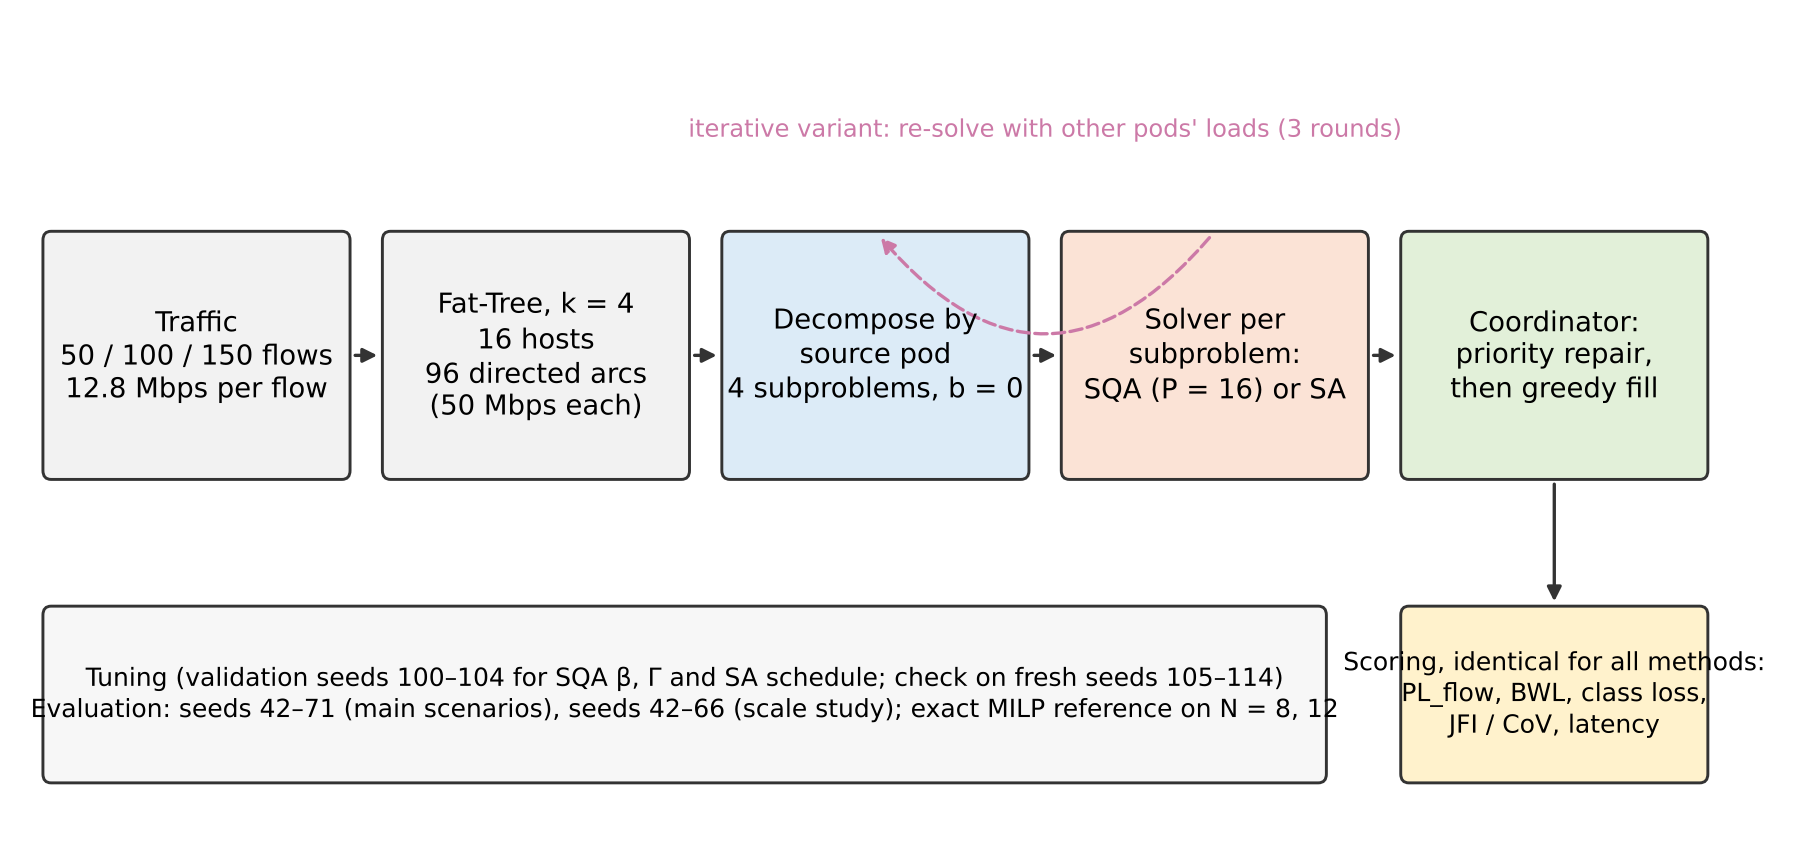

In [2]:
display(Image(filename=os.path.join(A.FIG, 'fig01_pipeline.png'), width=760))

Figure 1. Study pipeline and experimental protocol. Traffic is decomposed by source pod into four QUBO subproblems. Each subproblem is solved by SQA or SA under a matched sweep budget. A coordinator applies priority-ordered repair and greedy fill, and all methods are scored identically. The iterative variant re-solves the pods with the other pods' loads. Validation seeds (100–104; fresh check 105–114) are used for tuning only; evaluation uses seeds 42–71 (main) and 42–66 (scale).

**Figure 1.** Study pipeline and experimental protocol. Traffic is decomposed by source pod into four QUBO subproblems. Each subproblem is solved by SQA or SA under a matched sweep budget. A coordinator applies priority-ordered repair and greedy fill, and all methods are scored identically. The iterative variant re-solves the pods with the other pods' loads. Validation seeds (100–104; fresh check 105–114) are used for tuning only; evaluation uses seeds 42–71 (main) and 42–66 (scale).

Figure 1 shows where each design decision enters the study. Traffic and topology are fixed for each seed. The solver stage and the decomposition by source pod are the only parts that differ between the pipeline and the monolithic methods. The coordinator and the scoring are shared by all methods, so any difference in the reported loss must come from the solver stage or from the decomposition. Tuning uses validation seeds only, and the evaluation seeds are never used to choose a setting.

### 3.1 Network model

We use a k = 4 Fat-Tree [2]. It is a standard multi-rooted data-center topology, and it offers several equal-cost paths between pods, which is the setting in which the forwarding problem of Section 2.1 arises. The network has four pods, each with two edge and two aggregation switches, together with four core switches and 16 hosts (two per edge switch): 20 switches and 48 full-duplex physical links (Figure 2). Each physical link is modelled as two directed arcs of capacity c = 50 Mbps, giving 96 capacity constraints. Modelling arcs rather than links matters because the two directions of a link carry independent traffic. Counting a link once would hide congestion in one direction.

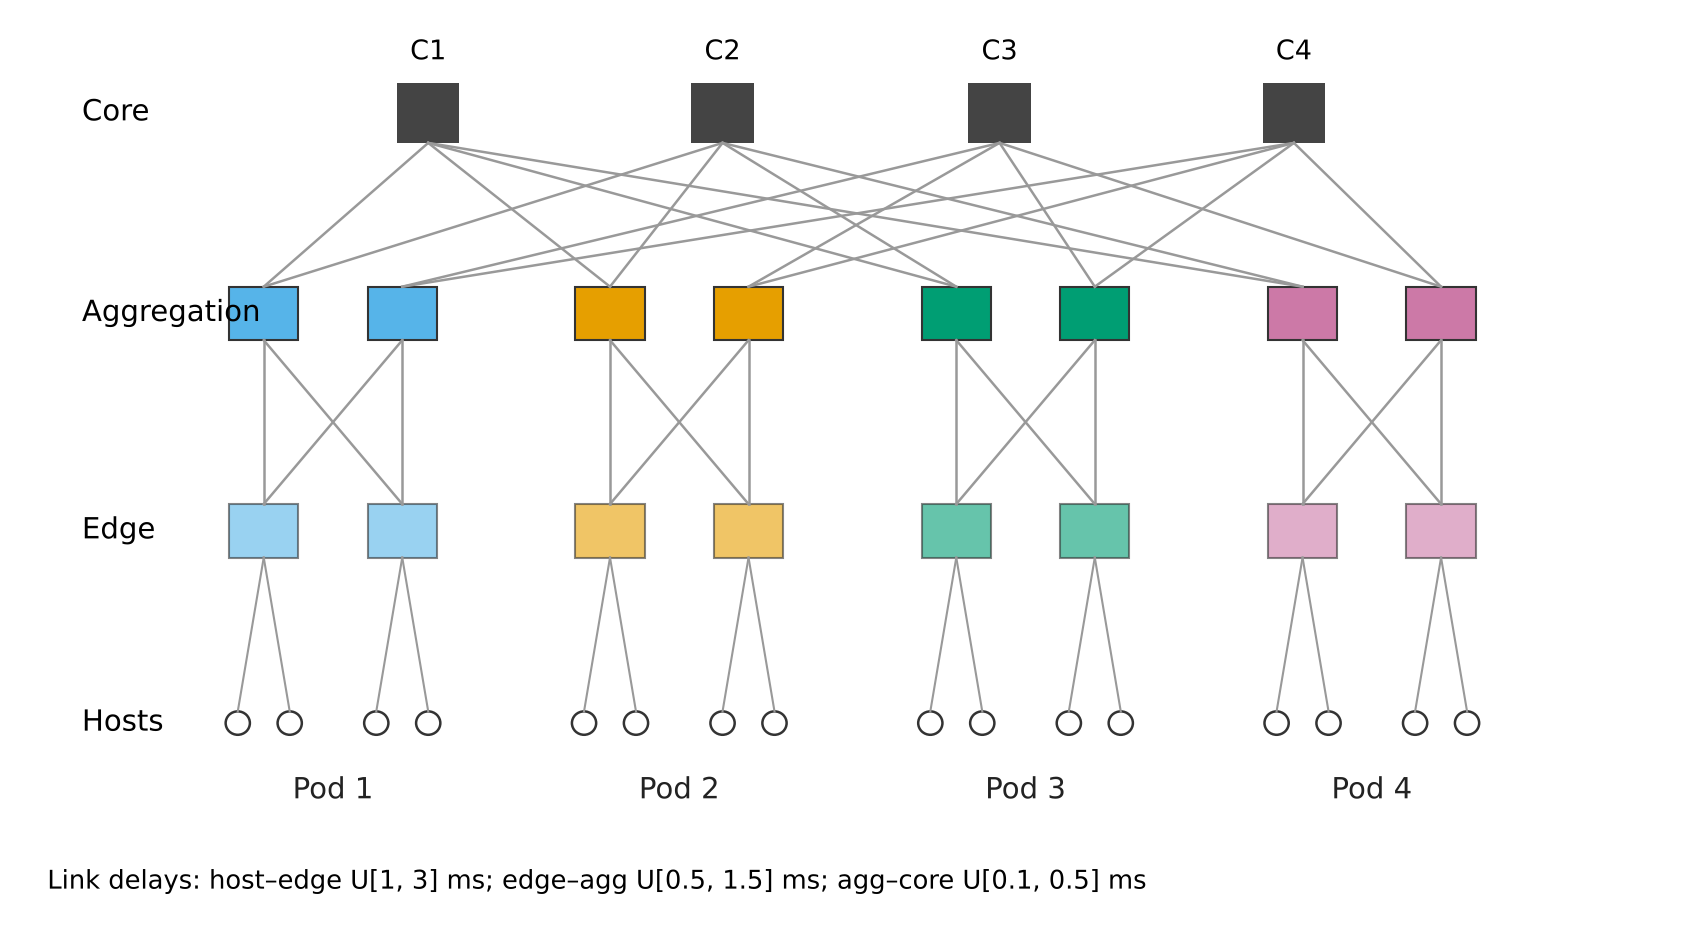

In [3]:
display(Image(filename=os.path.join(A.FIG, 'fig02_topology.png'), width=760))

Figure 2. Fat-Tree (k = 4) topology used in all experiments: 4 core, 8 aggregation and 8 edge switches, 16 hosts, 48 physical links. Colours mark pods. Link delays are sampled per run: host–edge U[1, 3] ms, edge–aggregation U[0.5, 1.5] ms, aggregation–core U[0.1, 0.5] ms.

**Figure 2.** Fat-Tree (k = 4) topology used in all experiments: 4 core, 8 aggregation and 8 edge switches, 16 hosts, 48 physical links. Colours mark pods. Link delays are sampled per run: host–edge U[1, 3] ms, edge–aggregation U[0.5, 1.5] ms, aggregation–core U[0.1, 0.5] ms.

Figure 2 shows the topology and the pod colouring used in the later analyses. The host–edge tier has the widest sampling interval of the three tiers, so host attachment contributes the largest share of the variation in path delay.

Propagation delays are sampled once per run from tier-specific intervals, with the same delay in both directions. The normalization constant is D_max = 2(3.0 + 1.5 + 0.5) = 10 ms, the largest six-hop inter-pod delay under these bounds. It is an interval bound, not a sampled maximum. Candidate paths are the Fat-Tree shortest paths: one for hosts on the same edge switch, two within a pod and four between pods, sorted by delay. Restricting candidates to shortest paths keeps the QUBO small and matches the path set that a standard ECMP fabric uses, so the optimizers and the ECMP baselines choose among the same paths.

### 3.2 Traffic and scenarios

The main experiments use three scenarios: S1 with 50 flows and a total demand of 640 Mbps, S2 with 100 flows and 1278.3 Mbps, and S3 with 150 flows and 1920 Mbps. In each scenario the mean demand is about 12.8 Mbps per flow. The scenarios therefore differ in the number of flows that compete for the same fabric, not in the size of an individual flow. This matters for interpretation, because a rising flow count raises the load on the fabric, and the three scenarios span a range of congestion levels.

Raw demands follow a Pareto distribution with shape 2 and minimum 2 Mbps, scaled so that they sum to the scenario total. A heavy-tailed distribution is used because data-center traffic is commonly described as dominated by a few large flows, and those are the flows whose placement matters most. Classes are assigned by flow count: 10% EF, 30% AF and 60% BE, with priority weights 3, 2 and 1.

The scale study keeps the per-flow demand at 12.8 Mbps and sets D = 12.8·N for N ∈ {50, 100, 200, 300}. Demand per flow is held constant, so the number of flows is not confounded with the congestion level. Under the constant-demand rule, the scale study addresses RQ4.

### 3.3 QUBO formulation

The formulation has three ingredients: a binary variable for admission, a binary variable for path choice, and binary slack bits that turn each capacity inequality into an equality that a QUBO can represent. Penalty terms enforce the constraints, and additional terms encode the objectives.

Variables. y_f ∈ {0,1} indicates that flow f is admitted; x_{f,p} ∈ {0,1} indicates that f uses candidate path p; s_{l,k} ∈ {0,1}, k = 0,…,K−1 with K = 6, are slack bits for arc l. Let d_f be the demand of f, b_l the background load on arc l from other pods (zero in the pod stage), and δ = c/(2^K − 1).

Objective. H = λ_A H_A + λ_c H_cap + λ_l H_bal + λ_t H_lat + λ_b H_bw + λ_f H_fair, with λ = (10, 10, 5, 3, 2, 1) for the baseline configuration.

One-hot admission: H_A = Σ_f (Σ_p x_{f,p} − y_f)².

Capacity with binary slack, in utilization units: H_cap = Σ_l ([Σ_f d_f Σ_{p∋l} x_{f,p} + Σ_k δ 2^k s_{l,k} + b_l − c]/c)².

Balance: with u_l = (b_l + Σ_f d_f Σ_{p∋l} x_{f,p})/c, H_bal = Σ_l u_l² − (1/|E|)(Σ_l u_l)², |E| = 96.

Priority-weighted latency: H_lat = Σ_f Σ_p w_f (D_p/D_max) x_{f,p}.

Bandwidth: H_bw = −Σ_f (d_f/D_tot) y_f (the constant term is dropped).

Served-bandwidth fairness: ρ_k = (1/D_k) Σ_{f∈k} d_f y_f, where D_k is the demand of class k, and H_fair = Σ_{k<k'} (ρ_k − ρ_{k'})². A count-based version let the solver reject nearly all flows and was replaced.

The one-hot and capacity terms are soft penalties, so a solver output may violate them. The study does not rely on the penalty weights to produce feasible results. The coordinator of Section 3.4 enforces hard capacity on every method's output, so the penalty weights affect solution quality but not the feasibility of the reported assignments. The baseline weights were fixed before the experiments and were not tuned; their sensitivity is not evaluated here (Section 4.9). As a check of the energy function, exhaustive enumeration on one small instance (3 flows, 2 links, 8,192 states) confirms that the minimum energy of the QUBO corresponds to the optimal assignment. This check covers the energy function only, not the Fat-Tree experiments.

### 3.4 Repair coordinator and decomposition

Repair is part of each method, not a post-processing choice. An overloaded arc drops every flow that crosses it (Section 4.3), so an unrepaired output has no meaningful loss value. The coordinator therefore defines the feasible set for every method, and all methods are compared on that common set.

The pipeline (MAS-QA) groups flows by source pod and solves each pod with b_l = 0, so a pod does not see the traffic of the other pods. The coordinator then processes flows in priority order (EF, then AF, then BE, larger demand first within a class). A flow whose path crosses an arc with load above c is moved to a candidate path with residual capacity, or rejected. Rejected flows are then admitted greedily on the first feasible path. The coordinator is deterministic and is applied to every method's output. The iterated variant (ITER-SQA-v2-R3) re-solves each pod for three rounds with background loads from the other pods. We report the Jacobi version. A Gauss–Seidel variant was tried on a small seed set only and is not reported.

### 3.5 Solvers, tuning and matched budgets

Both solvers are OpenJij samplers (SQASampler and SASampler) [27]. For SQA, the Trotter number is P = 16, and the inverse temperature β and the transverse field Γ were selected on validation seeds 100–104 and checked on fresh seeds 105–114, giving β = 0.5 and Γ = 1.0 (Figure 3a, 3c). For SA, the monolithic schedule was selected from four candidates on validation seeds 100–104: the OpenJij default, β ∈ [0.1, 3], β ∈ [0.1, 10] and β ∈ [5, 14]. The selected schedule is β ∈ [0.1, 10] (Figure 3b). Because this selection uses a small grid, the OpenJij default schedule is also reported as a second SA comparator (SA-mono-m) in all tables. Tuning on validation seeds and checking on fresh seeds keeps the reported comparison from being optimistic about the seeds used for the final evaluation.

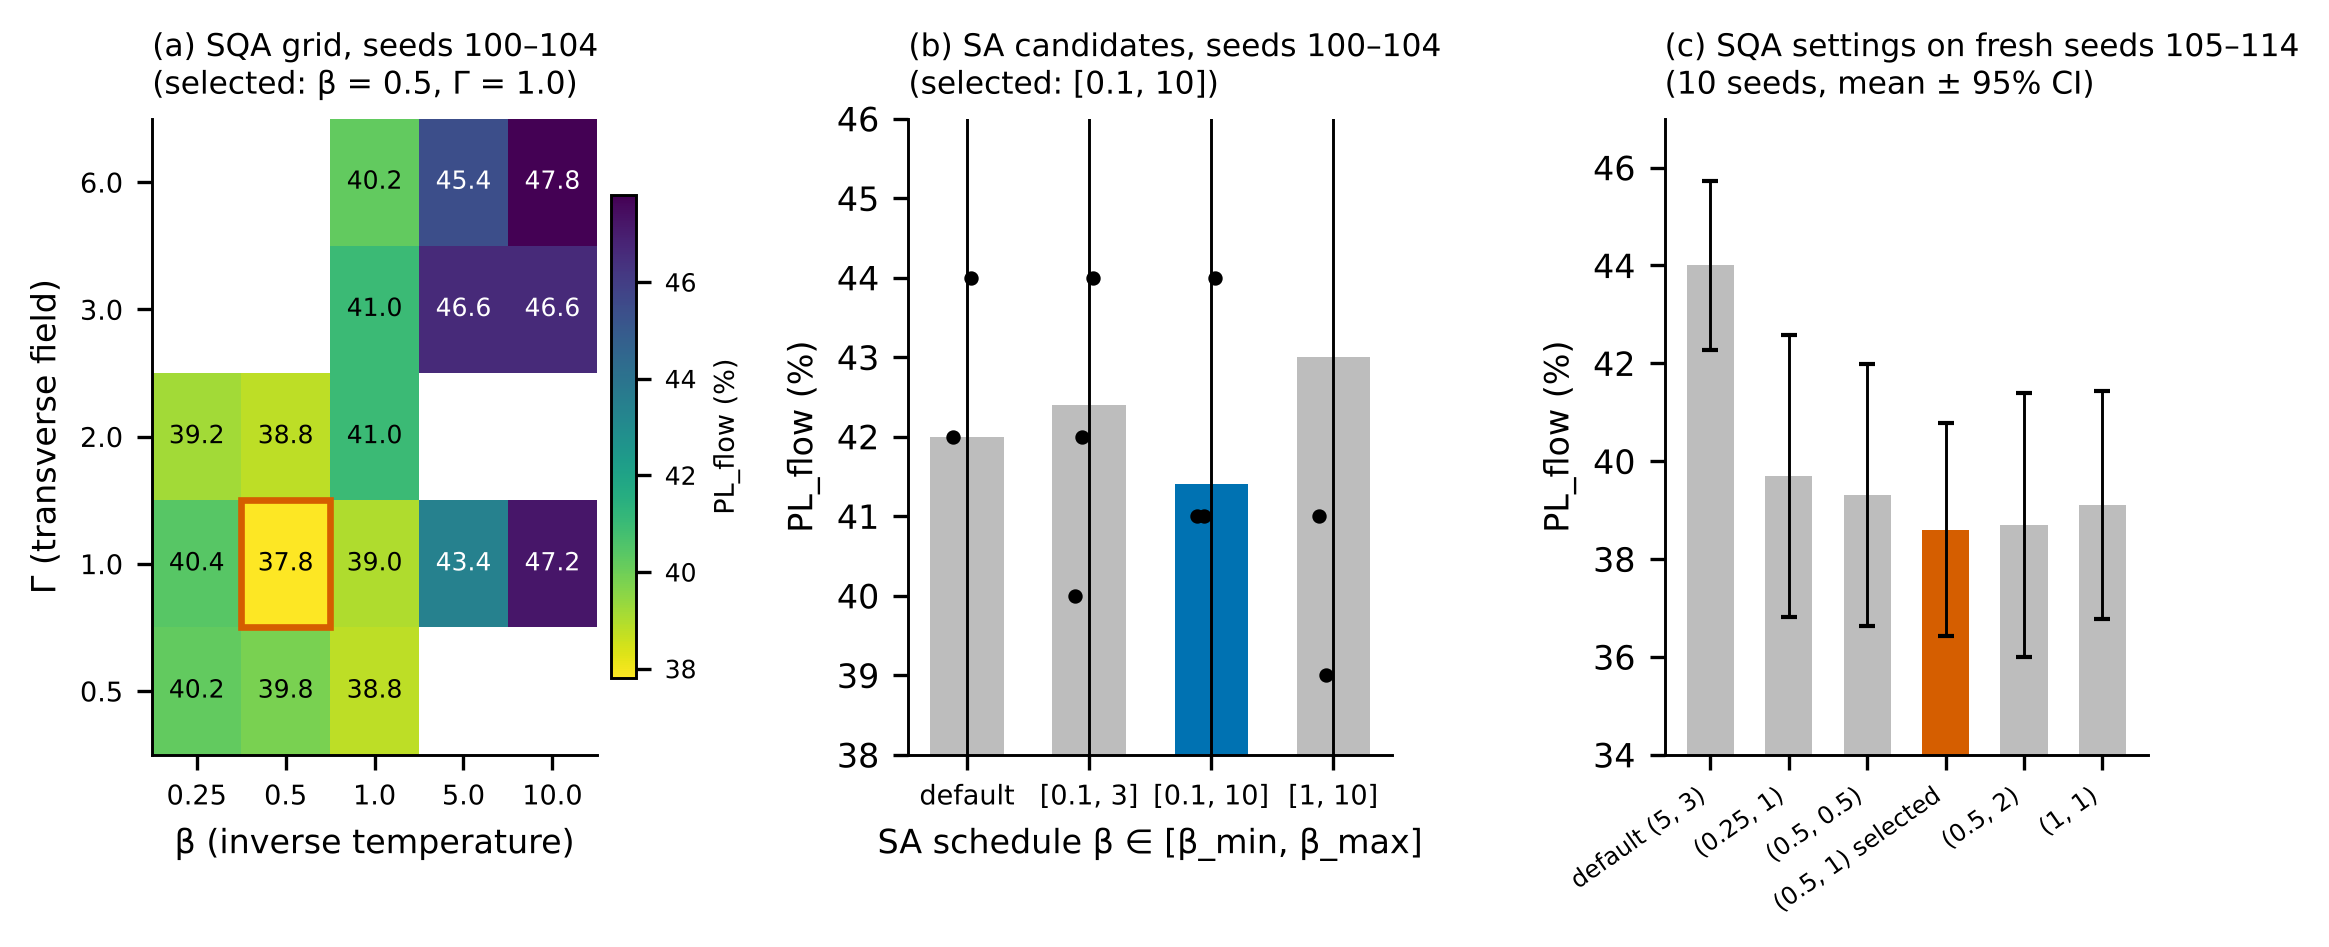

In [4]:
display(Image(filename=os.path.join(A.FIG, 'fig03_validation_tuning.png'), width=760))

Figure 3. Solver tuning on validation seeds only. (a) Mean PL_flow of SQA over the β × Γ grid on seeds 100–104; the selected setting (β = 0.5, Γ = 1.0) is outlined. (b) SA schedule candidates on seeds 100–104 (dots: individual seeds; bars: mean ± 95% CI); the selected schedule is β ∈ [0.1, 10]. (c) SQA settings on fresh seeds 105–114 (10 seeds, mean ± 95% CI).

**Figure 3.** Solver tuning on validation seeds only. (a) Mean PL_flow of SQA over the β × Γ grid on seeds 100–104; the selected setting (β = 0.5, Γ = 1.0) is outlined. (b) SA schedule candidates on seeds 100–104 (dots: individual seeds; bars: mean ± 95% CI); the selected schedule is β ∈ [0.1, 10]. (c) SQA settings on fresh seeds 105–114 (10 seeds, mean ± 95% CI).

Figure 3 documents the tuning. In panel (a), the SQA grid has a clear minimum at β = 0.5 and Γ = 1.0 among the settings tried, with a mean PL_flow of 37.8%, against 43% to 48% at β of 5 or more. Panel (b) shows that the four SA schedules differ by about 1.6 pp on the validation seeds, and that the selected schedule has the lowest mean. Panel (c) checks the selected SQA setting on seeds that were not used for selection. It has the lowest mean of the six settings shown, although the confidence intervals overlap with several alternatives, so the choice is a reasonable setting rather than a proven optimum.

Budgets. The two monolithic solvers are matched to each other by spin-update count, as defined in protocol3.py: the monolithic SQA uses 10 reads of 5000 sweeps with 16 Trotter slices, and the monolithic SA uses 10 reads of 80000 sweeps, which equals 5000 sweeps times 16 slices. Spin-update count is a proxy for annealing work, not a measure of wall-clock time. The pipeline is not matched to the monolithic solvers at the tuned budget. Its four pod solves together perform about one-sixth of the monolithic annealing work (ratio 6.2 in S1 and 6.1 in S2, computed from the recorded problem sizes and sweep counts). An equal-work control, in which the monolithic SQA receives the same total work as the pods, is therefore reported separately with the initial solver settings (Section 4.2). The pod SA variant (MAS+SA-m) uses 8000 sweeps per pod. Wall-clock matching was not validated (Section 4.7).

### 3.6 Methods compared

The methods form a ladder, and each step isolates one factor. The first two are baselines without an optimizer. The greedy coordinator adds the repair logic without a solver. The two SA variants and the monolithic SQA test the solver, and the pipeline and its iterated variant test the decomposition.

ECMP-hash: hashed path per flow with no capacity check, so a flow is lost if any arc on its path is overloaded.

ECMP+adm: the hashed path with capacity-aware admission in arrival order.

Greedy-only: the coordinator applied to an empty assignment (no solver).

SA-mono-mt+repair: tuned monolithic SA plus the coordinator (primary SA comparator).

SA-mono-m+repair: monolithic SA with the OpenJij default schedule plus the coordinator.

SQA-mono-v2+repair: monolithic SQA (tuned) plus the coordinator.

MAS+SA-m: pod-decomposed SA with the coordinator.

MAS-QA-v2: pod-decomposed SQA (tuned) with the coordinator, the proposed pipeline.

ITER-SQA-v2-R3: MAS-QA-v2 with three rounds of background-aware re-solving.

Controls without repair (MAS-decomp-only, SQA-mono raw, SA-mono raw) and the equal-work control (SQA-mono-matched) were run in an earlier protocol with the initial SQA setting (β = 5, Γ = 3). They are reported only in Sections 4.2 and 4.3.

### 3.7 Metrics

PL_flow is the primary metric, because the admission objective is to keep as many flows as possible. It is the complement of the admitted fraction, so a lower value is better. The remaining metrics check whether a gain in PL_flow is bought with bandwidth, class fairness, latency or balance.

PL_flow (%): rejected or lost flows divided by N_F. Per-run values are integer multiples of 100/N_F.

BWL (%): bandwidth of rejected or lost flows divided by D_tot.

Latency: mean and 95th-percentile propagation delay of admitted flows (ms).

Class losses PL_EF, PL_AF, PL_BE (%): rejected flows of each class divided by the class size.

Fairness: JFI and CoV (%) of the 16 host egress loads.

PL_flow and BWL are surrogates. They do not model queueing, bursts or transport feedback, and latency is propagation delay only (Section 4.9).

### 3.8 Protocol and statistics

The design is paired. Traffic, path sets and background are fixed for each seed and shared by all methods, so each comparison removes the between-seed variance that is common to the two methods. Evaluation seeds are 42–71 for the main scenarios (30 seeds each) and 42–66 for the scale study (25 seeds for N = 50, 100 and 200, and 24 for N = 300, one seed missing). For each paired comparison we report the mean difference d̄ = A − B, its 95% t-interval, the two-sided paired t-test p-value. For the headline family the exact Wilcoxon signed-rank p-value [24] is also given (Table 4). Table 3 applies a Bonferroni correction [25] over a family of 24 comparisons. The headline SQA-versus-SA claim has its own family of seven settings (three main scenarios and four scale sizes; Table 4). No equivalence within ±1 pp is claimed for any comparison.

### 3.9 Small-instance exact reference

Exact solutions are available only for small instances. The small-instance reference therefore answers a narrower question than the main study: how far each heuristic lies from the optimum of the same model when the optimum is known. For N ∈ {8, 12} flows and load ratios r ∈ {0.8, 1.6}, the same admission-and-routing model is solved exactly with SciPy's milp (HiGHS) [26] under two objectives, maximum admitted count (OPT-count) and maximum admitted bandwidth (OPT-bw). Each setting uses 20 seeds (42–61). Total demand is D_tot = r · 12.8 · N Mbps, where 12.8 Mbps is the per-flow mean of the main and scale studies. The load ratio r therefore scales the offered load, and the flow size is the same as in the main study. The small instances are therefore used for relative comparison of heuristics, not for the absolute loss values of the main scenarios.

## 4. Results

### 4.1 Main comparison (RQ1)

Table 2. PL_flow (%), mean ± SD over 30 seeds per scenario (lower is better). Tuned SA and tuned SQA use validation-selected settings.

**Table 2.** PL_flow (%), mean ± SD over 30 seeds per scenario (lower is better). Tuned SA and tuned SQA use validation-selected settings.

_Table as printed in the article:_

| Method | S1 (50 flows) | S2 (100 flows) | S3 (150 flows) |
|---|---|---|---|
| ECMP+adm | 27.5 ± 6.8 | 49.0 ± 5.3 | 60.9 ± 3.9 |
| Greedy-only | 24.0 ± 7.4 | 49.1 ± 5.0 | 62.4 ± 3.0 |
| SA-mono (default schedule) + repair | 20.5 ± 5.4 | 42.8 ± 5.5 | 57.8 ± 3.3 |
| SA-mono (tuned) + repair | 20.3 ± 5.8 | 42.5 ± 4.8 | 55.8 ± 3.7 |
| MAS+SA-m (pod SA) | 19.9 ± 5.8 | 41.9 ± 5.3 | 56.7 ± 3.7 |
| SQA-mono (tuned) + repair | 20.1 ± 5.9 | 40.9 ± 3.4 | 53.4 ± 3.4 |
| MAS-QA-v2 (pod SQA, proposed) | 20.5 ± 5.6 | 41.3 ± 5.0 | 54.0 ± 4.0 |
| ITER-SQA-v2-R3 | 20.3 ± 5.6 | 41.2 ± 4.5 | 53.6 ± 4.0 |

In [5]:
print('Table 2: recomputed from data/')
A.table2(m)

Table 2: recomputed from data/


,S1,S2,S3
ECMP+adm,27.5 ± 6.8,49.0 ± 5.3,60.9 ± 3.9
Greedy-only,24.0 ± 7.4,49.1 ± 5.0,62.4 ± 3.0
SA-mono-m+repair,20.5 ± 5.4,42.8 ± 5.5,57.8 ± 3.3
SA-mono-mt+repair,20.3 ± 5.8,42.5 ± 4.8,55.8 ± 3.7
MAS+SA-m,19.9 ± 5.8,41.9 ± 5.3,56.7 ± 3.7
SQA-mono-v2+repair,20.1 ± 5.9,40.9 ± 3.4,53.4 ± 3.4
MAS-QA-v2,20.5 ± 5.6,41.3 ± 5.0,54.0 ± 4.0
ITER-SQA-v2-R3,20.3 ± 5.6,41.2 ± 4.5,53.6 ± 4.0


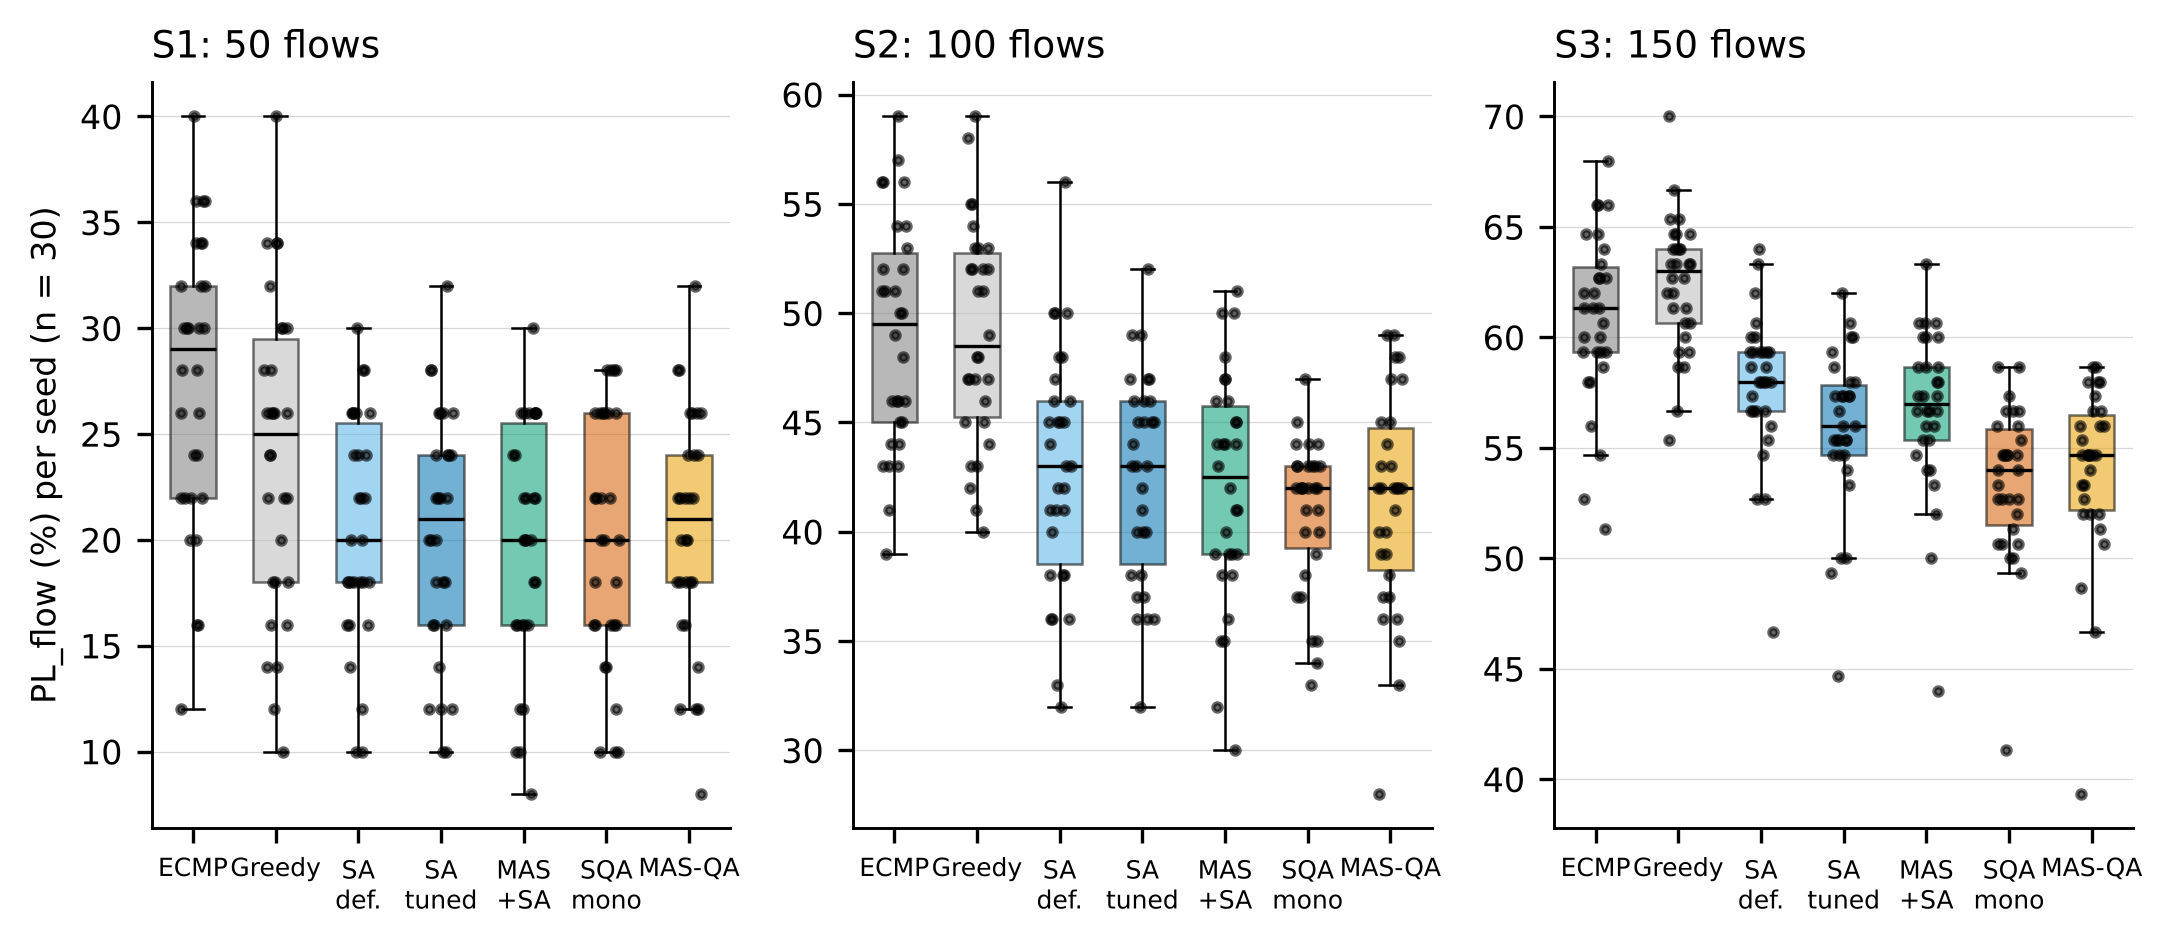

In [6]:
display(Image(filename=os.path.join(A.FIG, 'fig04_main_distributions.png'), width=760))

Figure 4. Per-seed flow loss (PL_flow, %) by method in S1 (50 flows), S2 (100 flows) and S3 (150 flows), n = 30 seeds each. Boxes show the interquartile range and median; dots are individual seeds.

**Figure 4.** Per-seed flow loss (PL_flow, %) by method in S1 (50 flows), S2 (100 flows) and S3 (150 flows), n = 30 seeds each. Boxes show the interquartile range and median; dots are individual seeds.

Figure 4 shows the per-seed distributions behind Table 2. The spread is wide in every scenario, with individual seeds spanning roughly 20 percentage points. A mean difference of one or two points is therefore small relative to seed-to-seed variation, and this is why the paired analysis of Section 4.2 is needed. Greedy and ECMP+adm sit highest in S2 and S3. The two SQA-based methods, SQA mono and MAS-QA, have the lowest or near-lowest medians in S2 and S3, and their medians are close to each other. MAS-QA has a few seeds with unusually low loss, which the paired analysis handles seed by seed.

Table 2 and Figure 4 give the main comparison. The greedy coordinator without a solver is 3.5, 7.8 and 8.4 pp worse than the proposed pipeline in S1, S2 and S3 (Table 3). Among the solver-based methods, the spread of the means is 1.9 pp in S2 and 4.4 pp in S3, with tuned SQA lowest in both. The proposed pipeline (MAS-QA-v2) and monolithic tuned SQA differ by at most 0.6 pp in every scenario. The lowest PL_flow in S1 is MAS+SA-m, but the differences among the solver-based methods in S1 are within noise (Table 3).

### 4.2 Paired comparisons, the headline SQA claim, and decomposition (RQ1, RQ2)

Table 3. Paired PL_flow differences d̄ = A − B (pp; negative favours A), 95% CI, paired t-test p, and Bonferroni-adjusted p over 24 tests.

**Table 3.** Paired PL_flow differences d̄ = A − B (pp; negative favours A), 95% CI, paired t-test p, and Bonferroni-adjusted p over 24 tests.

_Table as printed in the article:_

| Setting | A | B | d̄ | 95% CI | p | p_adj (m = 24) |
|---|---|---|---|---|---|---|
| S1 | SQA-mono-v2+repair | SA-mono-mt+repair | -0.20 | [-1.49, +1.09] | 0.754 | 1.000 |
| S1 | SQA-mono-v2+repair | SA-mono-m+repair | -0.40 | [-2.08, +1.28] | 0.630 | 1.000 |
| S1 | MAS-QA-v2 | SA-mono-mt+repair | +0.20 | [-1.23, +1.63] | 0.777 | 1.000 |
| S1 | MAS-QA-v2 | MAS+SA-m | +0.60 | [-0.92, +2.12] | 0.426 | 1.000 |
| S1 | MAS-QA-v2 | SQA-mono-v2+repair | +0.40 | [-0.94, +1.74] | 0.545 | 1.000 |
| S1 | MAS-QA-v2 | Greedy-only | -3.53 | [-5.77, -1.30] | 0.003 | 0.073 |
| S1 | MAS-QA-v2 | ECMP+adm | -7.00 | [-8.90, -5.10] | <0.001 | 0.000 |
| S1 | ITER-SQA-v2-R3 | MAS-QA-v2 | -0.13 | [-0.84, +0.57] | 0.702 | 1.000 |
| S2 | SQA-mono-v2+repair | SA-mono-mt+repair | -1.63 | [-2.65, -0.61] | 0.003 | 0.066 |
| S2 | SQA-mono-v2+repair | SA-mono-m+repair | -1.97 | [-3.21, -0.72] | 0.003 | 0.074 |
| S2 | MAS-QA-v2 | SA-mono-mt+repair | -1.20 | [-2.32, -0.08] | 0.037 | 0.894 |
| S2 | MAS-QA-v2 | MAS+SA-m | -0.63 | [-1.70, +0.43] | 0.235 | 1.000 |
| S2 | MAS-QA-v2 | SQA-mono-v2+repair | +0.43 | [-0.75, +1.62] | 0.460 | 1.000 |
| S2 | MAS-QA-v2 | Greedy-only | -7.77 | [-9.09, -6.44] | <0.001 | 0.000 |
| S2 | MAS-QA-v2 | ECMP+adm | -7.70 | [-9.53, -5.87] | <0.001 | 0.000 |
| S2 | ITER-SQA-v2-R3 | MAS-QA-v2 | -0.10 | [-0.89, +0.69] | 0.798 | 1.000 |
| S3 | SQA-mono-v2+repair | SA-mono-mt+repair | -2.36 | [-3.18, -1.53] | <0.001 | 0.000 |
| S3 | SQA-mono-v2+repair | SA-mono-m+repair | -4.40 | [-5.44, -3.36] | <0.001 | 0.000 |
| S3 | MAS-QA-v2 | SA-mono-mt+repair | -1.82 | [-2.74, -0.91] | <0.001 | 0.008 |
| S3 | MAS-QA-v2 | MAS+SA-m | -2.71 | [-3.45, -1.97] | <0.001 | 0.000 |
| S3 | MAS-QA-v2 | SQA-mono-v2+repair | +0.53 | [-0.22, +1.28] | 0.156 | 1.000 |
| S3 | MAS-QA-v2 | Greedy-only | -8.42 | [-9.79, -7.06] | <0.001 | 0.000 |
| S3 | MAS-QA-v2 | ECMP+adm | -6.89 | [-8.13, -5.65] | <0.001 | 0.000 |
| S3 | ITER-SQA-v2-R3 | MAS-QA-v2 | -0.38 | [-0.86, +0.10] | 0.118 | 1.000 |

In [7]:
print('Table 3: recomputed from data/')
A.table3(m)

Table 3: recomputed from data/


,setting,A,B,dbar,lo,hi,p,p_adj
0,S1,SQA-mono-v2+repair,SA-mono-mt+repair,-0.200000,-1.491285,1.091285,7.536840e-01,1.000000e+00
1,S1,SQA-mono-v2+repair,SA-mono-m+repair,-0.400000,-2.080256,1.280256,6.299995e-01,1.000000e+00
2,S1,MAS-QA-v2,SA-mono-mt+repair,0.200000,-1.232500,1.632500,7.772549e-01,1.000000e+00
3,S1,MAS-QA-v2,MAS+SA-m,0.600000,-0.921056,2.121056,4.263681e-01,1.000000e+00
4,S1,MAS-QA-v2,SQA-mono-v2+repair,0.400000,-0.935938,1.735938,5.450636e-01,1.000000e+00
5,S1,MAS-QA-v2,Greedy-only,-3.533333,-5.766749,-1.299918,3.029323e-03,7.270376e-02
6,S1,MAS-QA-v2,ECMP+adm,-7.000000,-8.898948,-5.101052,2.605513e-08,6.253231e-07
7,S1,ITER-SQA-v2-R3,MAS-QA-v2,-0.133333,-0.838648,0.571981,7.018509e-01,1.000000e+00
8,S2,SQA-mono-v2+repair,SA-mono-mt+repair,-1.633333,-2.654694,-0.611973,2.768407e-03,6.644176e-02
9,S2,SQA-mono-v2+repair,SA-mono-m+repair,-1.966667,-3.212791,-0.720543,3.090344e-03,7.416825e-02


Table 4. Headline claim: SQA-mono (tuned) minus SA-mono (tuned), paired by seed. Bonferroni-adjusted p over the family of seven settings (m = 7).

**Table 4.** Headline claim: SQA-mono (tuned) minus SA-mono (tuned), paired by seed. Bonferroni-adjusted p over the family of seven settings (m = 7).

_Table as printed in the article:_

| Setting | d̄ (pp) | 95% CI | p (t-test) | p_adj (m = 7) | Significant | p (Wilcoxon) |
|---|---|---|---|---|---|---|
| Main S1 | -0.20 | [-1.49, +1.09] | 0.754 | 1.000 | no | 0.791 |
| Main S2 | -1.63 | [-2.65, -0.61] | 0.003 | 0.019 | yes | 0.004 |
| Main S3 | -2.36 | [-3.18, -1.53] | <0.001 | 0.000 | yes | <0.001 |
| Scale N=50 | -0.32 | [-1.88, +1.24] | 0.675 | 1.000 | no | 0.755 |
| Scale N=100 | -2.48 | [-3.52, -1.44] | <0.001 | 0.000 | yes | <0.001 |
| Scale N=200 | -3.12 | [-3.85, -2.39] | <0.001 | 0.000 | yes | <0.001 |
| Scale N=300 | -2.40 | [-2.99, -1.81] | <0.001 | 0.000 | yes | <0.001 |

In [8]:
print('Table 4: recomputed from data/')
A.headline(m, sc)

Table 4: recomputed from data/


,setting,n,dbar,lo,hi,p,p_wilcoxon,p_adj_m7
0,S1,30,-0.200000,-1.491285,1.091285,7.536840e-01,0.791156,1.000000e+00
1,S2,30,-1.633333,-2.654694,-0.611973,2.768407e-03,0.003647,1.937885e-02
2,S3,30,-2.355556,-3.184374,-1.526738,2.666013e-06,0.000029,1.866209e-05
3,N=50,25,-0.320000,-1.876933,1.236933,6.751998e-01,0.754930,1.000000e+00
4,N=100,25,-2.480000,-3.519626,-1.440374,5.048350e-05,0.000203,3.533845e-04
5,N=200,25,-3.120000,-3.852805,-2.387195,5.761772e-09,0.000017,4.033240e-08
6,N=300,24,-2.402778,-2.992661,-1.812894,1.740202e-08,0.000018,1.218142e-07


Headline claim. Against the tuned SA, SQA loses fewer flows in S2 (-1.63 pp, p = 0.003) and S3 (-2.36 pp, p < 0.001) before correction; both remain significant after correction over the seven-setting family (Table 4, Figure 5a). In S1 the difference is not significant. In the scale study the same comparison is significant for N = 100, 200 and 300 and not for N = 50 (Section 4.5). Tuned SQA therefore loses 1.6 to 3.1 pp fewer flows than tuned SA at 100 or more flows under the same budget and repair. It is not a claim of consistent superiority at 50 flows.

The choice of SA schedule matters. With the OpenJij default schedule (SA-mono-m) instead of the tuned schedule, the gap in S3 grows to -4.40 pp. The tuned SA is the fairer comparator, so the reported gap is the conservative one. Because the SA schedule was chosen from four candidates, a bias in favour of SA cannot be excluded; such a bias would shrink the reported SQA advantage.

Decomposition at the tuned budget. The pipeline and monolithic SQA differ by at most 0.6 pp in the main scenarios, and not significantly (Table 3, Figure 5b). The monolithic runs, however, use about 6 times the annealing work of the pipeline, so at the tuned budget the comparison favours the pipeline on cost. Iterating the pods with background loads (ITER-SQA-v2-R3) changes PL_flow by between −0.38 and −0.10 pp, none significant (Figure 6).

Decomposition at equal annealing work. Giving the monolithic SQA the same total work as the four pod solves (SQA-mono-matched, with the initial solver settings) changes the picture (Table 5). The monolithic solver is better by 2.1 pp in S1 (paired t-test p = 0.003; p = 0.009 after correction over three scenarios). The differences in S2 (-0.4 pp, p = 0.408) and S3 (-0.6 pp, p = 0.062) are not significant. Decomposition therefore trades a small loss of solution quality at equal work, which is clear only at 50 flows, for a large reduction in the work of each solve. We regard that trade-off as the practical argument for decomposition, and we do not claim that decomposition improves solution quality.

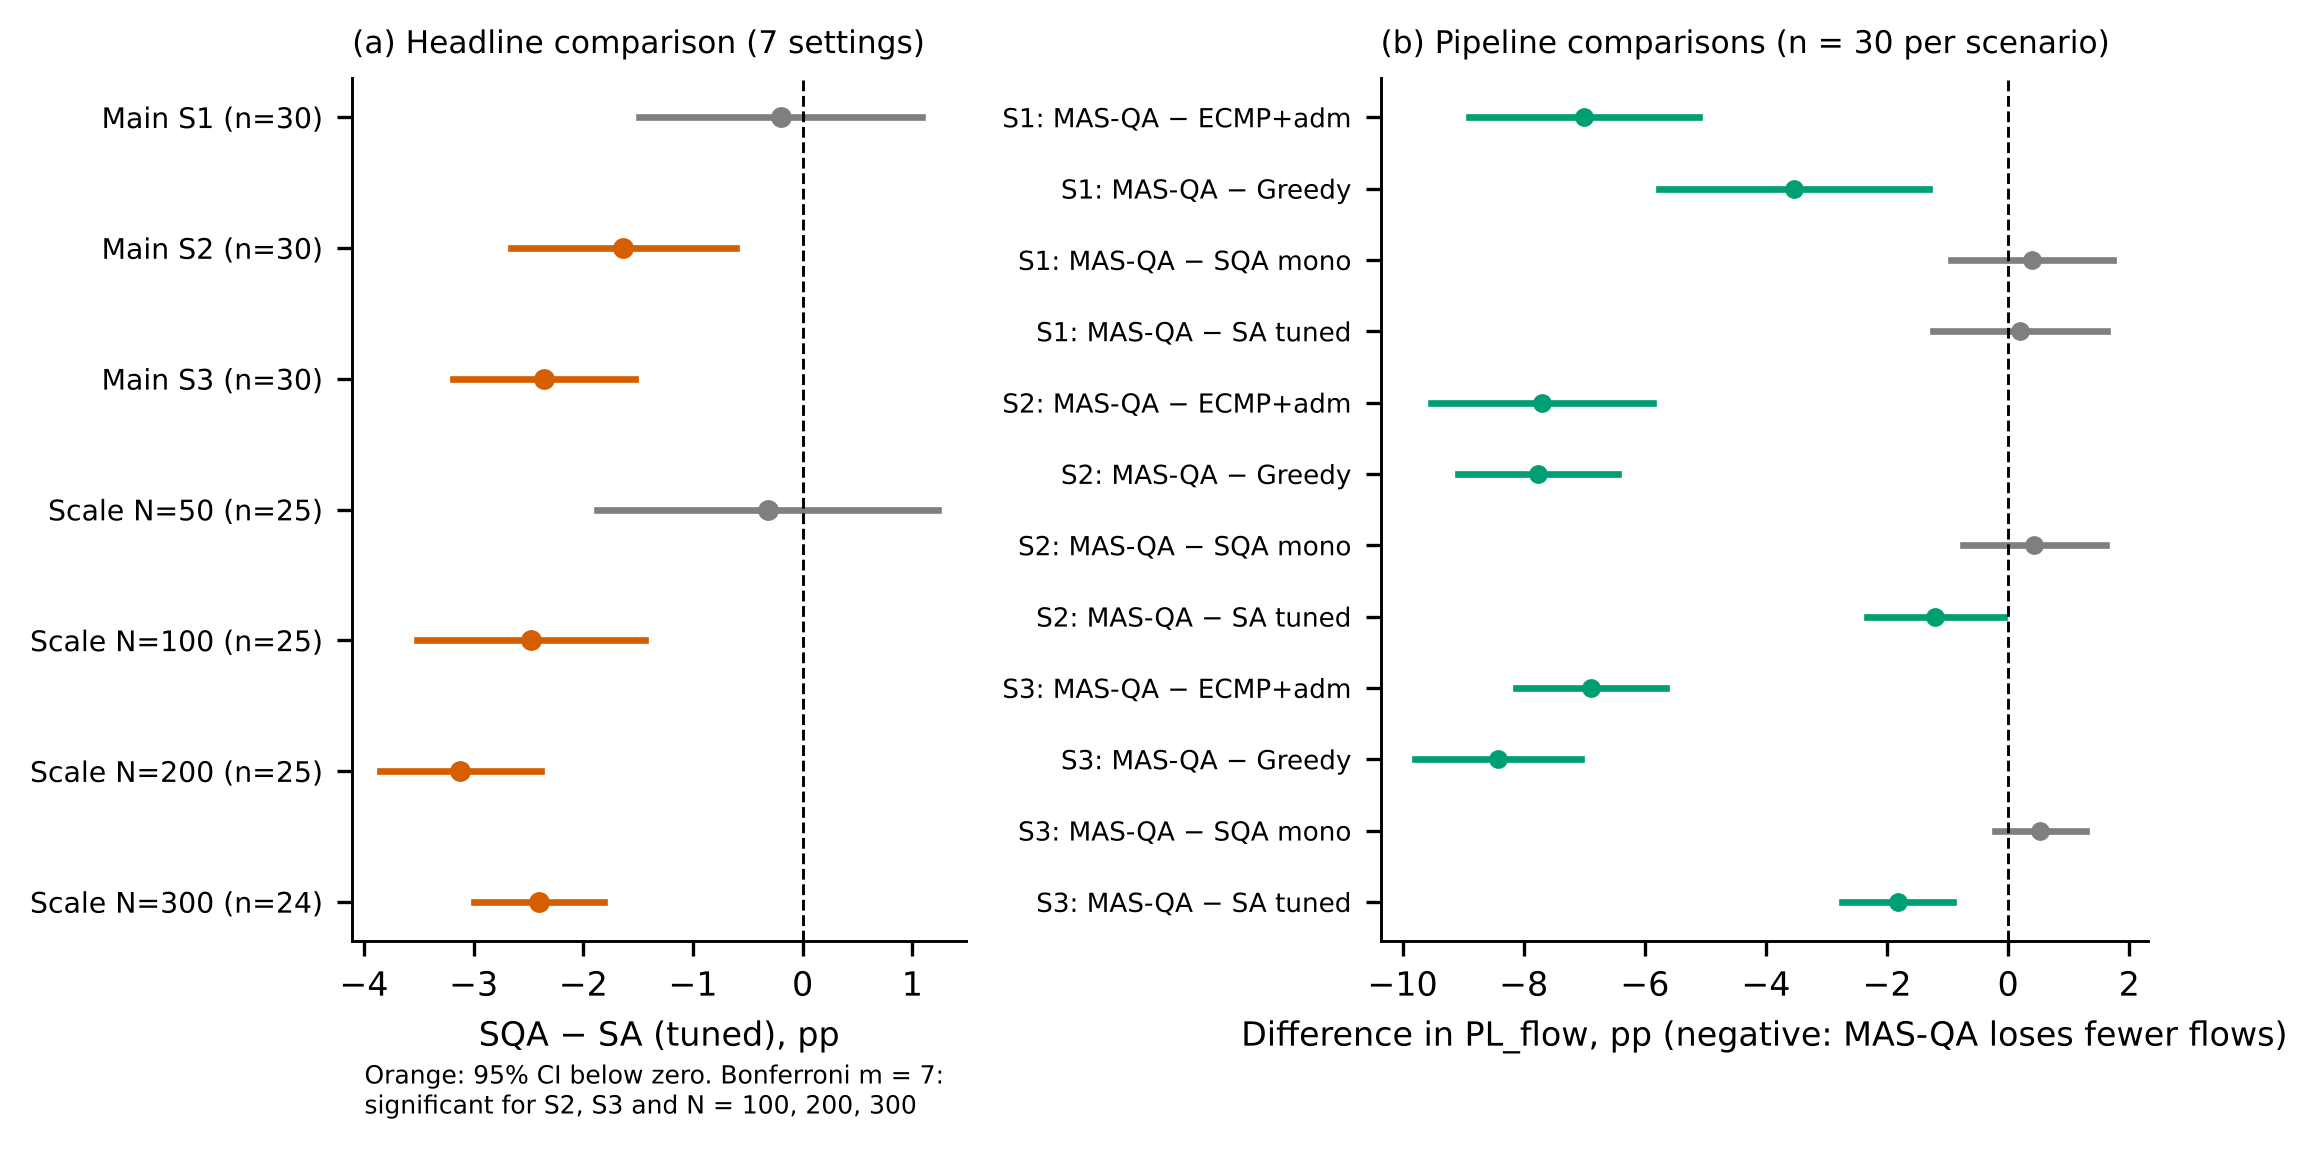

In [9]:
display(Image(filename=os.path.join(A.FIG, 'fig05_paired_differences.png'), width=760))

Figure 5. Paired differences with 95% confidence intervals, paired by seed. (a) Headline comparison, SQA minus tuned SA, in the three main scenarios and at N = 50–300 with constant per-flow demand (orange: unadjusted 95% CI below zero). Significance statements in the text use Bonferroni correction over the primary family of seven settings (m = 7), as in Table 4. (b) Pipeline comparisons in S1–S3: MAS-QA minus ECMP+adm, Greedy-only, monolithic SQA and tuned SA (green: CI below zero; orange: CI above zero; grey: CI includes zero). Negative values favour the first method.

**Figure 5.** Paired differences with 95% confidence intervals, paired by seed. (a) Headline comparison, SQA minus tuned SA, in the three main scenarios and at N = 50–300 with constant per-flow demand (orange: unadjusted 95% CI below zero). Significance statements in the text use Bonferroni correction over the primary family of seven settings (m = 7), as in Table 4. (b) Pipeline comparisons in S1–S3: MAS-QA minus ECMP+adm, Greedy-only, monolithic SQA and tuned SA (green: CI below zero; orange: CI above zero; grey: CI includes zero). Negative values favour the first method.

Figure 5 converts the comparisons into paired differences with 95% confidence intervals. Panel (a) shows the headline claim. Tuned SQA minus tuned SA is negative in S2 and S3, and at every scale size of 100 or more flows. In these settings the interval excludes zero after the seven-setting correction, and they are shown in orange. The difference is indistinguishable from zero in S1 and at N = 50. Panel (b) shows that the proposed pipeline lies far below ECMP+adm and Greedy in every scenario, and is not distinguishable from monolithic SQA. Its difference from tuned SA is smaller, about one to two points in S2 and S3, and the S2 interval lies just below zero (upper limit −0.08 pp).

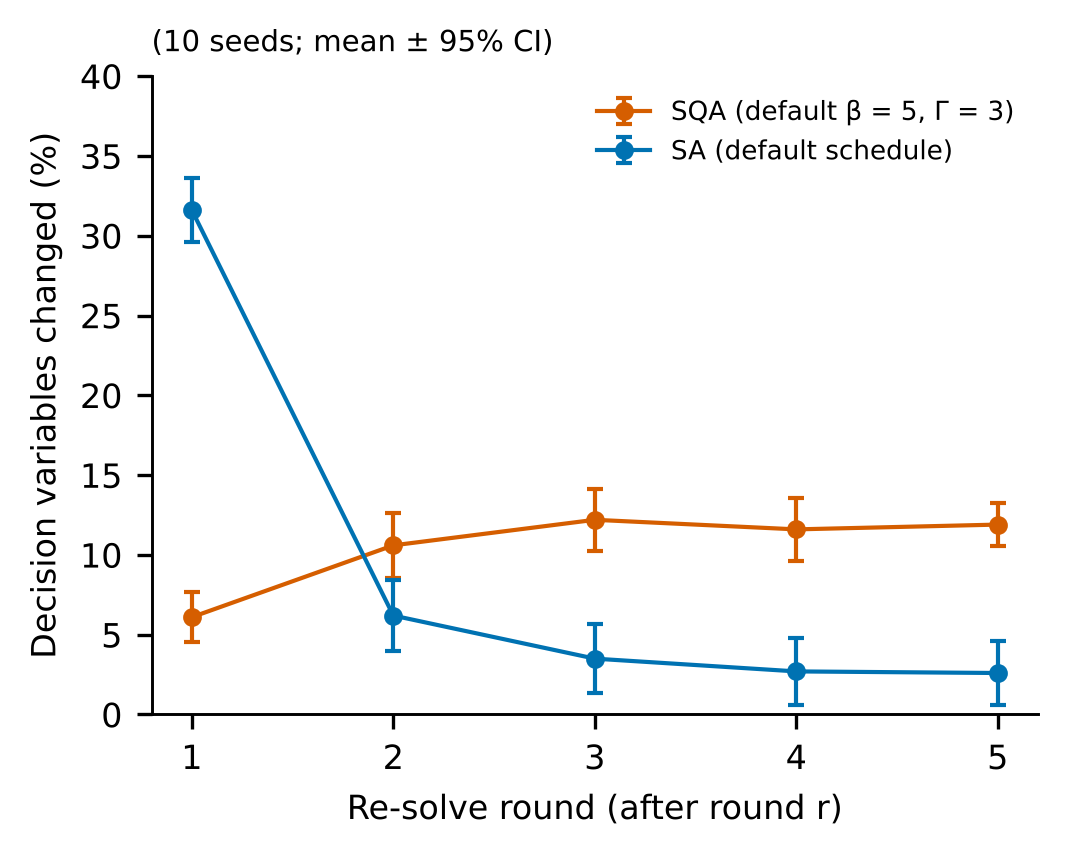

In [10]:
display(Image(filename=os.path.join(A.FIG, 'fig06_iteration_change.png'), width=760))

Figure 6. Round-to-round change in the iterated pod solves: percentage of decision variables that change after each re-solve round (10 seeds, mean ± 95% CI). The SQA curve uses the default setting (β = 5, Γ = 3), because convergence was recorded only for that setting. The SA curve uses its default schedule.

**Figure 6.** Round-to-round change in the iterated pod solves: percentage of decision variables that change after each re-solve round (10 seeds, mean ± 95% CI). The SQA curve uses the default setting (β = 5, Γ = 3), because convergence was recorded only for that setting. The SA curve uses its default schedule.

Figure 6 shows how many decision variables change when each pod is re-solved with the other pods' loads. For SA, the first re-solve changes about 32% of the variables, and the share then settles below 5%. For SQA with the initial setting, the share stays between about 6% and 12% over five rounds and does not settle. The iteration therefore does not converge within the rounds tested. This is consistent with the absence of a significant gain from iteration reported in Section 4.2.

### 4.3 What repair and the solver contribute (RQ2)

Table 5. Controls from the earlier protocol (initial SQA setting β = 5, Γ = 3; 30 seeds per scenario). PL_flow (%), mean. Rows without repair bound the comparison.

**Table 5.** Controls from the earlier protocol (initial SQA setting β = 5, Γ = 3; 30 seeds per scenario). PL_flow (%), mean. Rows without repair bound the comparison.

_Table as printed in the article:_

| Control | S1 | S2 | S3 |
|---|---|---|---|
| ECMP-hash | 84.5 | 99.7 | 100.0 |
| ECMP+adm | 27.5 | 49.0 | 60.9 |
| Greedy-only (repair, no solver) | 24.0 | 49.1 | 62.4 |
| MAS-decomp-only (no repair) | 89.7 | 94.2 | 96.4 |
| SQA-mono raw (no repair) | 83.5 | 89.0 | 93.0 |
| SA-mono raw (no repair) | 52.8 | 73.2 | 82.5 |
| SQA-mono + repair (initial settings) | 21.4 | 46.2 | 59.7 |
| SQA-mono, equal work + repair (initial settings) | 20.5 | 46.4 | 60.0 |
| MAS-QA + repair (initial settings) | 22.6 | 46.8 | 60.6 |

In [11]:
print('Table 5: recomputed from data/')
A.table5(ea)

Table 5: recomputed from data/


,S1,S2,S3
ECMP-hash,84.5,99.7,100.0
ECMP+adm,27.5,49.0,60.9
"Greedy-only (repair, no solver)",24.0,49.1,62.4
MAS-decomp-only (no repair),89.7,94.2,96.4
SQA-mono raw (no repair),83.5,89.0,93.0
SA-mono raw (no repair),52.8,73.2,82.5
SQA-mono + repair (initial settings),21.4,46.2,59.7
"SQA-mono, equal work + repair (initial settings)",20.5,46.4,60.0
MAS-QA + repair (initial settings),22.6,46.8,60.6


Without repair, solver outputs are infeasible at this load: unrepaired outputs lose 53–96% of flows (Table 5), because an overloaded arc drops every flow that crosses it. Repair is therefore necessary for any solver to be usable, and it is the largest single factor (Figure 7). Given repair, the solver adds 3.5, 7.8 and 8.4 pp over the greedy coordinator without a solver in S1, S2 and S3 (Table 3). These differences are significant before correction in all three scenarios; after Bonferroni correction over 24 tests, S2 and S3 remain significant and S1 does not. The greedy coordinator alone is no better than capacity-aware ECMP at 100 and 150 flows, so the solver accounts for the gain over ECMP at those sizes. The repair is necessary, but the gain over ECMP depends on the solver.

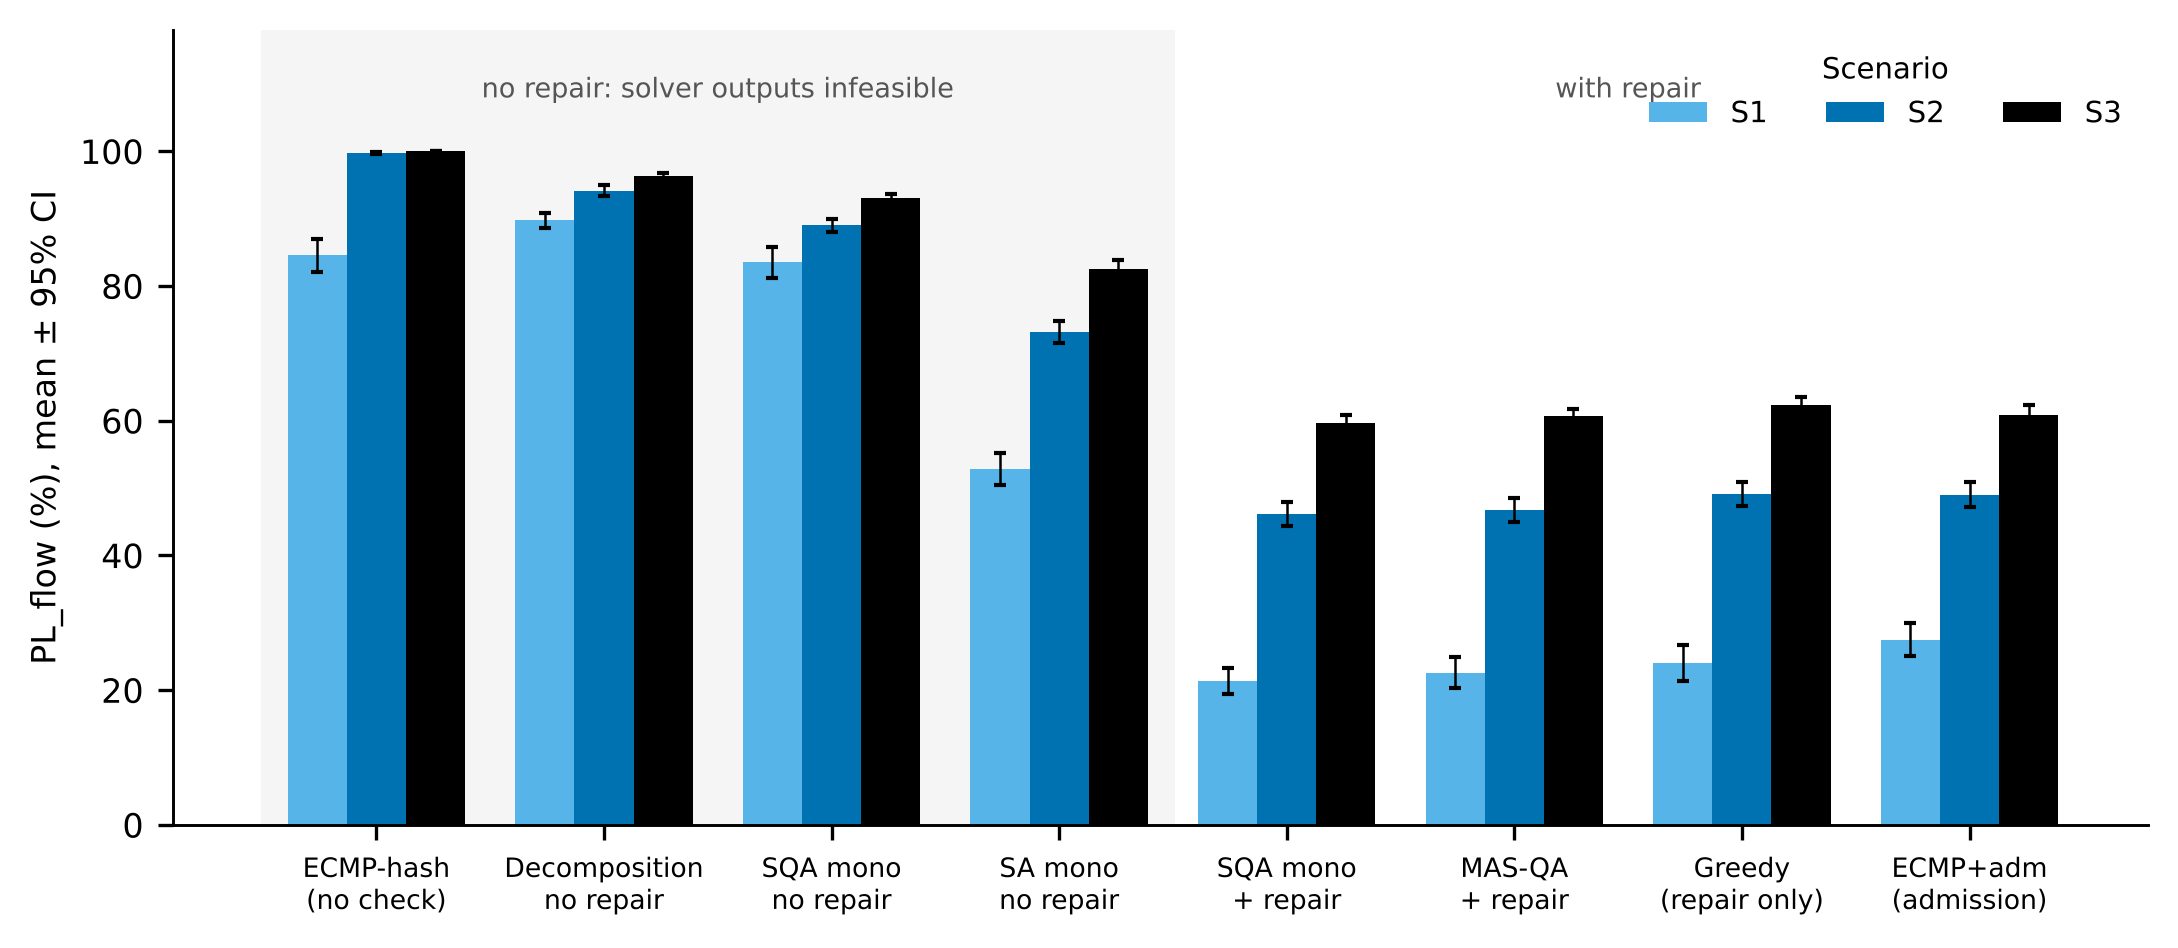

In [12]:
display(Image(filename=os.path.join(A.FIG, 'fig07_repair_ablation.png'), width=760))

Figure 7. Effect of the repair step, using the initial SQA setting (β = 5, Γ = 3). PL_flow (%), mean ± 95% CI over 30 seeds per scenario. The shaded region shows unrepaired outputs, which are infeasible at this load.

**Figure 7.** Effect of the repair step, using the initial SQA setting (β = 5, Γ = 3). PL_flow (%), mean ± 95% CI over 30 seeds per scenario. The shaded region shows unrepaired outputs, which are infeasible at this load.

Figure 7 isolates the role of repair, using the initial SQA setting. Without repair, every solver-based variant loses between about 53% and 96% of flows, because an overloaded arc drops all the flows that cross it. With repair, the three methods that share the coordinator, SQA mono, MAS-QA and Greedy, fall into a narrow band. The figure therefore supports the claim that most of the final result comes from the coordinator. The solver adds a smaller increment on top of it than in the tuned comparison of Section 4.1: from Table 5, about 1.4 to 2.9 pp for this setting, compared with 3.5 to 8.4 pp in Section 4.1. Table 5 gives the exact values.

Priority ordering and class protection. Table 6 and Figure 8 report class-specific losses. The priority order does not translate into strong EF protection under the solver-based pipelines. Under MAS-QA-v2, EF loss is 20.7%, 34.3% and 53.1% in S1, S2 and S3, against 22.0%, 50.7% and 62.0% for ECMP+adm, so the reduction is modest. The greedy coordinator, which admits flows strictly in priority order, reaches EF loss of 2.0%, 4.3% and 4.7%, but at the cost of 35–84% BE loss. The QUBO has no explicit class-priority term beyond the latency weights, so a solver that optimizes the total objective does not reproduce the priority order. A priority-aware objective is a candidate for future work.

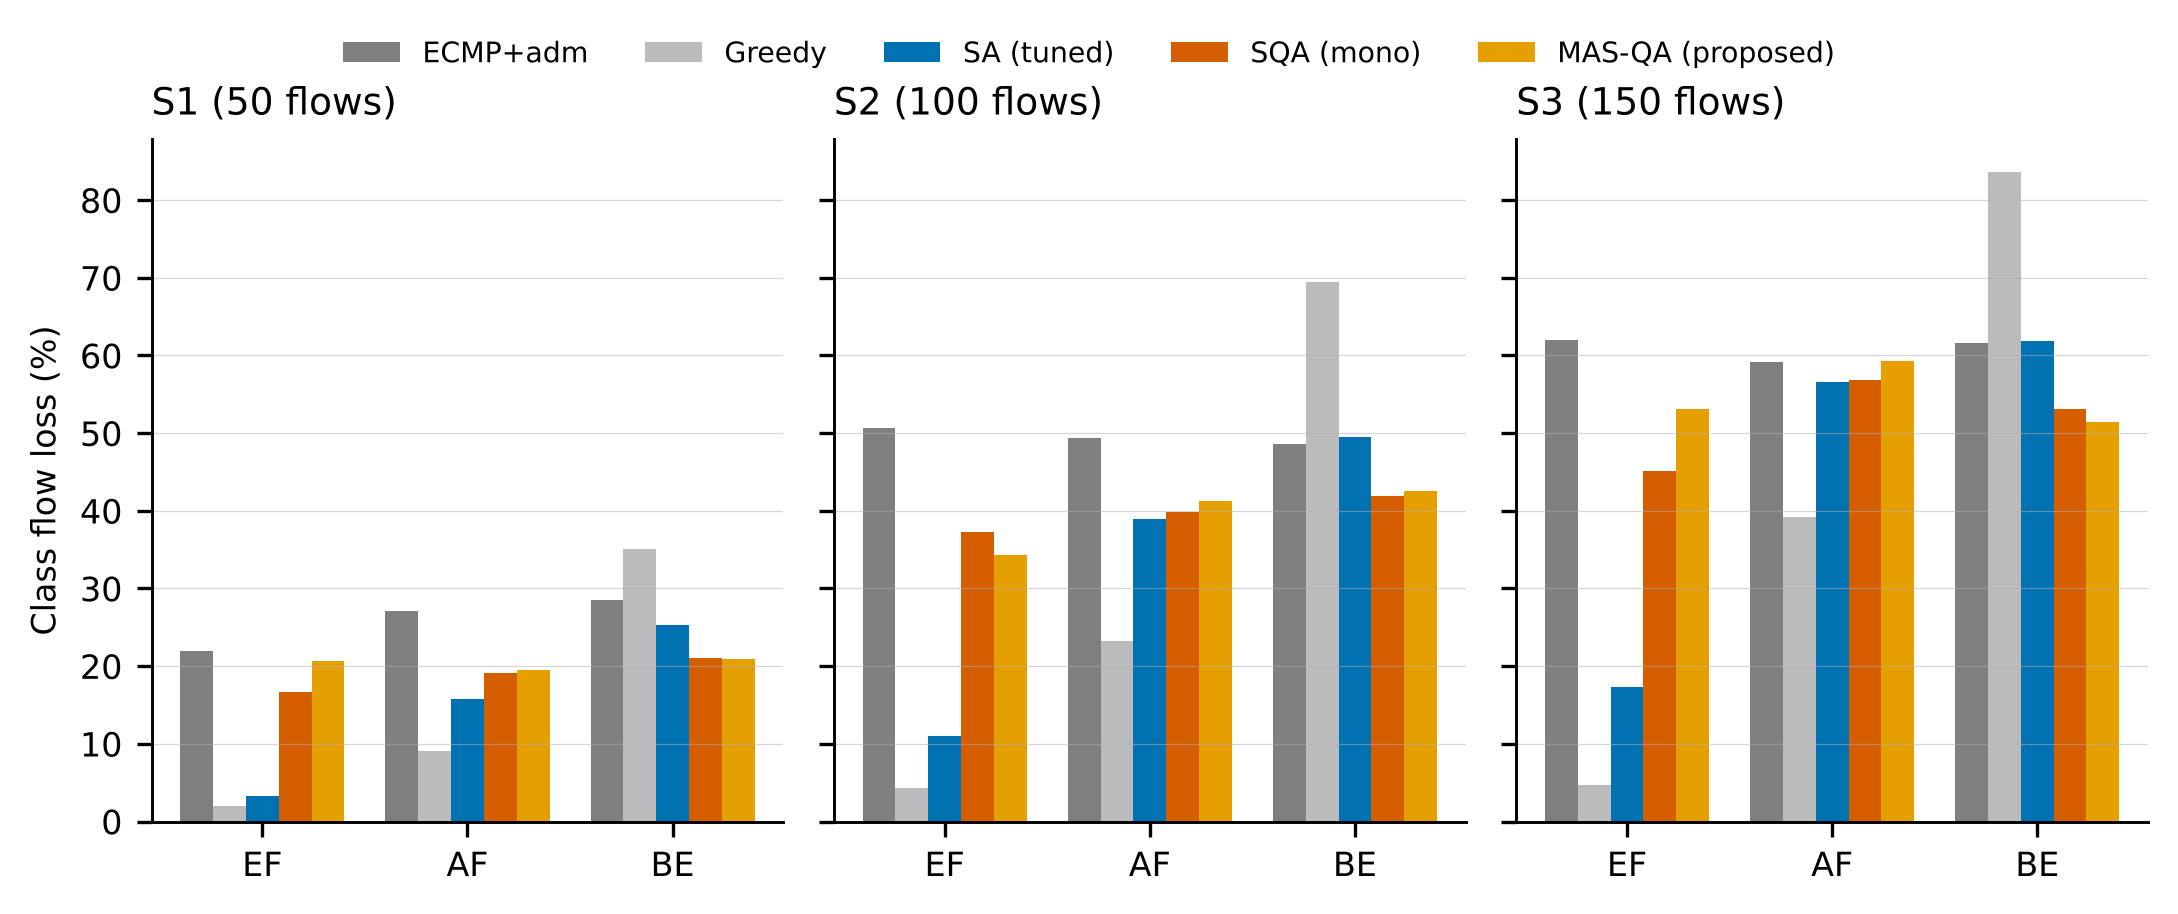

In [13]:
display(Image(filename=os.path.join(A.FIG, 'fig08_class_loss.png'), width=760))

Figure 8. Class-specific flow loss (EF, AF and BE; %) in S1, S2 and S3 (means over 30 seeds). Methods are ECMP+adm, greedy repair without a solver, tuned SA, monolithic SQA and MAS-QA.

**Figure 8.** Class-specific flow loss (EF, AF and BE; %) in S1, S2 and S3 (means over 30 seeds). Methods are ECMP+adm, greedy repair without a solver, tuned SA, monolithic SQA and MAS-QA.

Figure 8 shows class-specific loss. The EF class is the one the priority ordering is meant to protect, and the figure shows that the SQA-based pipelines do not protect it well. EF loss under SQA mono and MAS-QA is 17% to 21% in S1 and 34% to 53% in S2 and S3. Tuned SA loses less EF traffic than both SQA-based methods in all three scenarios, and Greedy keeps EF loss near 2% to 5% in S2 and S3, because it admits flows in priority order. The EF advantage of Greedy is paid for in BE loss, which reaches about 70% in S2 and 84% in S3. The solver-based methods spread the loss more evenly across classes, which is consistent with their lower aggregate PL_flow, but the figure shows that this comes at a cost to the highest-priority class.

### 4.4 Fairness, latency and tail behaviour

Table 6. Class-specific loss (%), fairness and latency (means over 30 seeds).

**Table 6.** Class-specific loss (%), fairness and latency (means over 30 seeds).

_Table as printed in the article:_

| Scen. | Method | PL_EF | PL_AF | PL_BE | JFI | CoV (%) | Lat. mean (ms) | Lat. p95 (ms) |
|---|---|---|---|---|---|---|---|---|
| S1 | ECMP+adm | 22.0 | 27.1 | 28.6 | 0.773 | 54.1 | 6.51 | 8.01 |
| S1 | Greedy | 2.0 | 9.1 | 35.1 | 0.780 | 53.1 | 6.36 | 7.91 |
| S1 | SA-mono (tuned) | 3.3 | 15.8 | 25.3 | 0.800 | 49.9 | 6.40 | 7.97 |
| S1 | SQA-mono | 16.7 | 19.1 | 21.1 | 0.801 | 49.8 | 6.47 | 8.03 |
| S1 | MAS-QA-v2 | 20.7 | 19.6 | 20.9 | 0.789 | 51.7 | 6.47 | 8.02 |
| S2 | ECMP+adm | 50.7 | 49.3 | 48.6 | 0.876 | 37.3 | 6.47 | 8.08 |
| S2 | Greedy | 4.3 | 23.2 | 69.4 | 0.914 | 30.5 | 6.39 | 7.98 |
| S2 | SA-mono (tuned) | 11.0 | 39.0 | 49.5 | 0.923 | 28.4 | 6.44 | 8.02 |
| S2 | SQA-mono | 37.3 | 39.9 | 41.9 | 0.926 | 27.8 | 6.50 | 8.04 |
| S2 | MAS-QA-v2 | 34.3 | 41.2 | 42.5 | 0.914 | 30.4 | 6.51 | 8.05 |
| S3 | ECMP+adm | 62.0 | 59.1 | 61.6 | 0.914 | 30.4 | 6.50 | 8.10 |
| S3 | Greedy | 4.7 | 39.2 | 83.6 | 0.945 | 23.7 | 6.45 | 8.01 |
| S3 | SA-mono (tuned) | 17.3 | 56.6 | 61.8 | 0.961 | 19.7 | 6.50 | 8.09 |
| S3 | SQA-mono | 45.1 | 56.9 | 53.1 | 0.957 | 20.8 | 6.53 | 8.12 |
| S3 | MAS-QA-v2 | 53.1 | 59.3 | 51.5 | 0.957 | 20.7 | 6.51 | 8.10 |

In [14]:
print('Table 6: recomputed from data/')
A.table6(m)

Table 6: recomputed from data/


,scenario,method,PL_EF,PL_AF,PL_BE,JFI,CoV,lat_mean,lat_p95
0,S1,ECMP+adm,22.000000,27.111111,28.555556,0.773259,54.092810,6.511559,8.014829
1,S1,Greedy,2.000000,9.111111,35.111111,0.779908,53.053294,6.361318,7.906674
2,S1,SA (tuned),3.333333,15.777778,25.333333,0.799956,49.911564,6.401314,7.966560
3,S1,SQA (mono),16.666667,19.111111,21.111111,0.800914,49.757362,6.474448,8.031614
4,S1,MAS-QA-v2,20.666667,19.555556,20.888889,0.788618,51.697271,6.468171,8.024287
5,S2,ECMP+adm,50.666667,49.333333,48.555556,0.876180,37.329690,6.468603,8.075817
6,S2,Greedy,4.333333,23.222222,69.444444,0.913541,30.451834,6.385825,7.981541
7,S2,SA (tuned),11.000000,39.000000,49.500000,0.923500,28.437096,6.443167,8.019246
8,S2,SQA (mono),37.333333,39.888889,41.944444,0.926234,27.839266,6.504023,8.039592
9,S2,MAS-QA-v2,34.333333,41.222222,42.500000,0.913680,30.373695,6.508343,8.045560


Latency is not a discriminating metric in these scenarios: admitted flows use short paths, and mean latency varies by about 0.2 ms across the methods. JFI rises with load for all methods. The solver-based methods have higher JFI than ECMP+adm in every scenario (0.79–0.80 against 0.77 in S1; 0.91–0.93 against 0.88 in S2; 0.96 against 0.91 in S3; Table 6). Learned methods were not evaluated, so no fairness ranking against them is claimed.

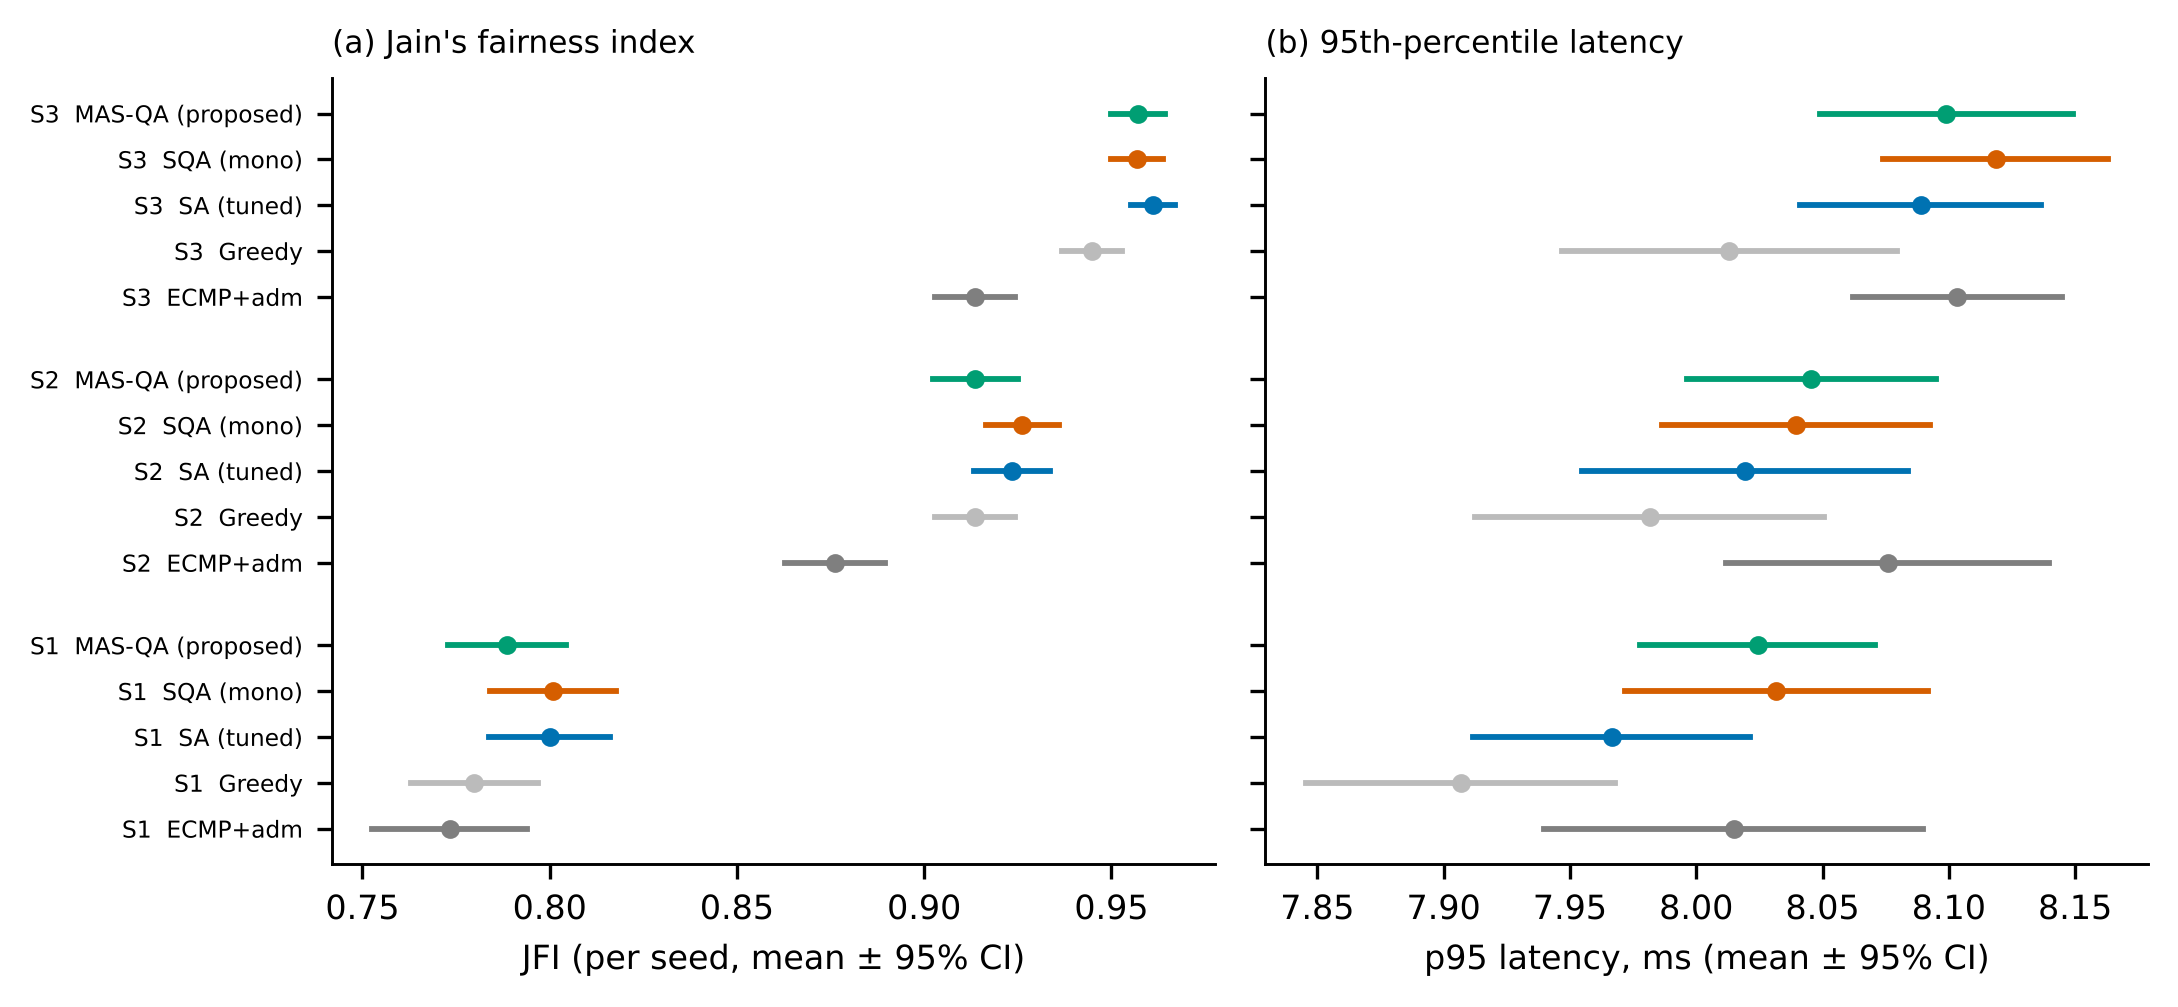

In [15]:
display(Image(filename=os.path.join(A.FIG, 'fig09_fairness_latency.png'), width=760))

Figure 9. Fairness and tail latency by method and scenario, per seed (30 seeds). (a) Jain's fairness index (JFI) and (b) 95th-percentile per-flow latency, both shown as mean with 95% confidence interval. Methods: ECMP+adm, Greedy, SA (tuned), SQA (monolithic, tuned) and MAS-QA (proposed).

**Figure 9.** Fairness and tail latency by method and scenario, per seed (30 seeds). (a) Jain's fairness index (JFI) and (b) 95th-percentile per-flow latency, both shown as mean with 95% confidence interval. Methods: ECMP+adm, Greedy, SA (tuned), SQA (monolithic, tuned) and MAS-QA (proposed).

Figure 9 shows the same fairness and latency results as Table 6, with the spread across seeds. Panel (a) confirms that ECMP+adm has the lowest JFI in every scenario, and that the solver-based methods lie above it. Within each scenario the intervals of SA (tuned), SQA (monolithic) and MAS-QA overlap, so the figure does not separate the solvers on fairness. Panel (b) places the p95 latency of all methods between about 7.9 and 8.2 ms. The intervals overlap substantially within each scenario, which confirms that latency does not discriminate between the methods in these scenarios.

### 4.5 Scale study with constant per-flow demand (RQ4)

Table 7. PL_flow (%) with per-flow demand fixed at 12.8 Mbps, mean over 24–25 seeds.

**Table 7.** PL_flow (%) with per-flow demand fixed at 12.8 Mbps, mean over 24–25 seeds.

_Table as printed in the article:_

| N_F | ECMP+adm | Greedy-only | SA-mono (tuned) | SQA-mono | MAS-QA-v2 |
|---|---|---|---|---|---|
| 50 | 28.2 | 24.2 | 20.5 | 20.2 | 20.3 |
| 100 | 49.2 | 49.1 | 43.2 | 40.7 | 41.0 |
| 200 | 68.0 | 70.6 | 65.3 | 62.2 | 62.2 |
| 300 | 77.5 | 79.9 | 75.3 | 72.9 | 73.0 |

In [16]:
print('Table 7: recomputed from data/')
A.table7(sc)

Table 7: recomputed from data/


,ECMP+adm,Greedy-only,SA-mono-mt+repair,SQA-mono-v2+repair,MAS-QA-v2
50,28.160000,24.160000,20.480000,20.160000,20.320000
100,49.160000,49.080000,43.160000,40.680000,41.000000
200,68.020000,70.600000,65.300000,62.180000,62.180000
300,77.486111,79.888889,75.291667,72.888889,73.027778


Table 8. Paired differences (pp): SQA-mono minus tuned SA, and MAS-QA-v2 minus ECMP+adm.

**Table 8.** Paired differences (pp): SQA-mono minus tuned SA, and MAS-QA-v2 minus ECMP+adm.

_Table as printed in the article:_

| N_F | SQA − SA d̄ | 95% CI | p | MAS-QA − ECMP d̄ | 95% CI | p |
|---|---|---|---|---|---|---|
| 50 | -0.32 | [-1.88, +1.24] | 0.675 | -7.84 | [-9.67, -6.01] | <0.001 |
| 100 | -2.48 | [-3.52, -1.44] | <0.001 | -8.16 | [-10.11, -6.21] | <0.001 |
| 200 | -3.12 | [-3.85, -2.39] | <0.001 | -5.84 | [-6.83, -4.85] | <0.001 |
| 300 | -2.40 | [-2.99, -1.81] | <0.001 | -4.46 | [-5.22, -3.70] | <0.001 |

In [17]:
print('Table 8: recomputed from data/')
A.table8(sc)

Table 8: recomputed from data/


,N,sqa_minus_sa,sqa_ci_lo,sqa_ci_hi,sqa_p,mas_minus_ecmp,mas_ci_lo,mas_ci_hi,mas_p
0,50,-0.320000,-1.876933,1.236933,6.751998e-01,-7.840000,-9.669317,-6.010683,5.098986e-09
1,100,-2.480000,-3.519626,-1.440374,5.048350e-05,-8.160000,-10.105911,-6.214089,7.627287e-09
2,200,-3.120000,-3.852805,-2.387195,5.761772e-09,-5.840000,-6.832890,-4.847110,9.835723e-12
3,300,-2.402778,-2.992661,-1.812894,1.740202e-08,-4.458333,-5.217809,-3.698858,1.742460e-11


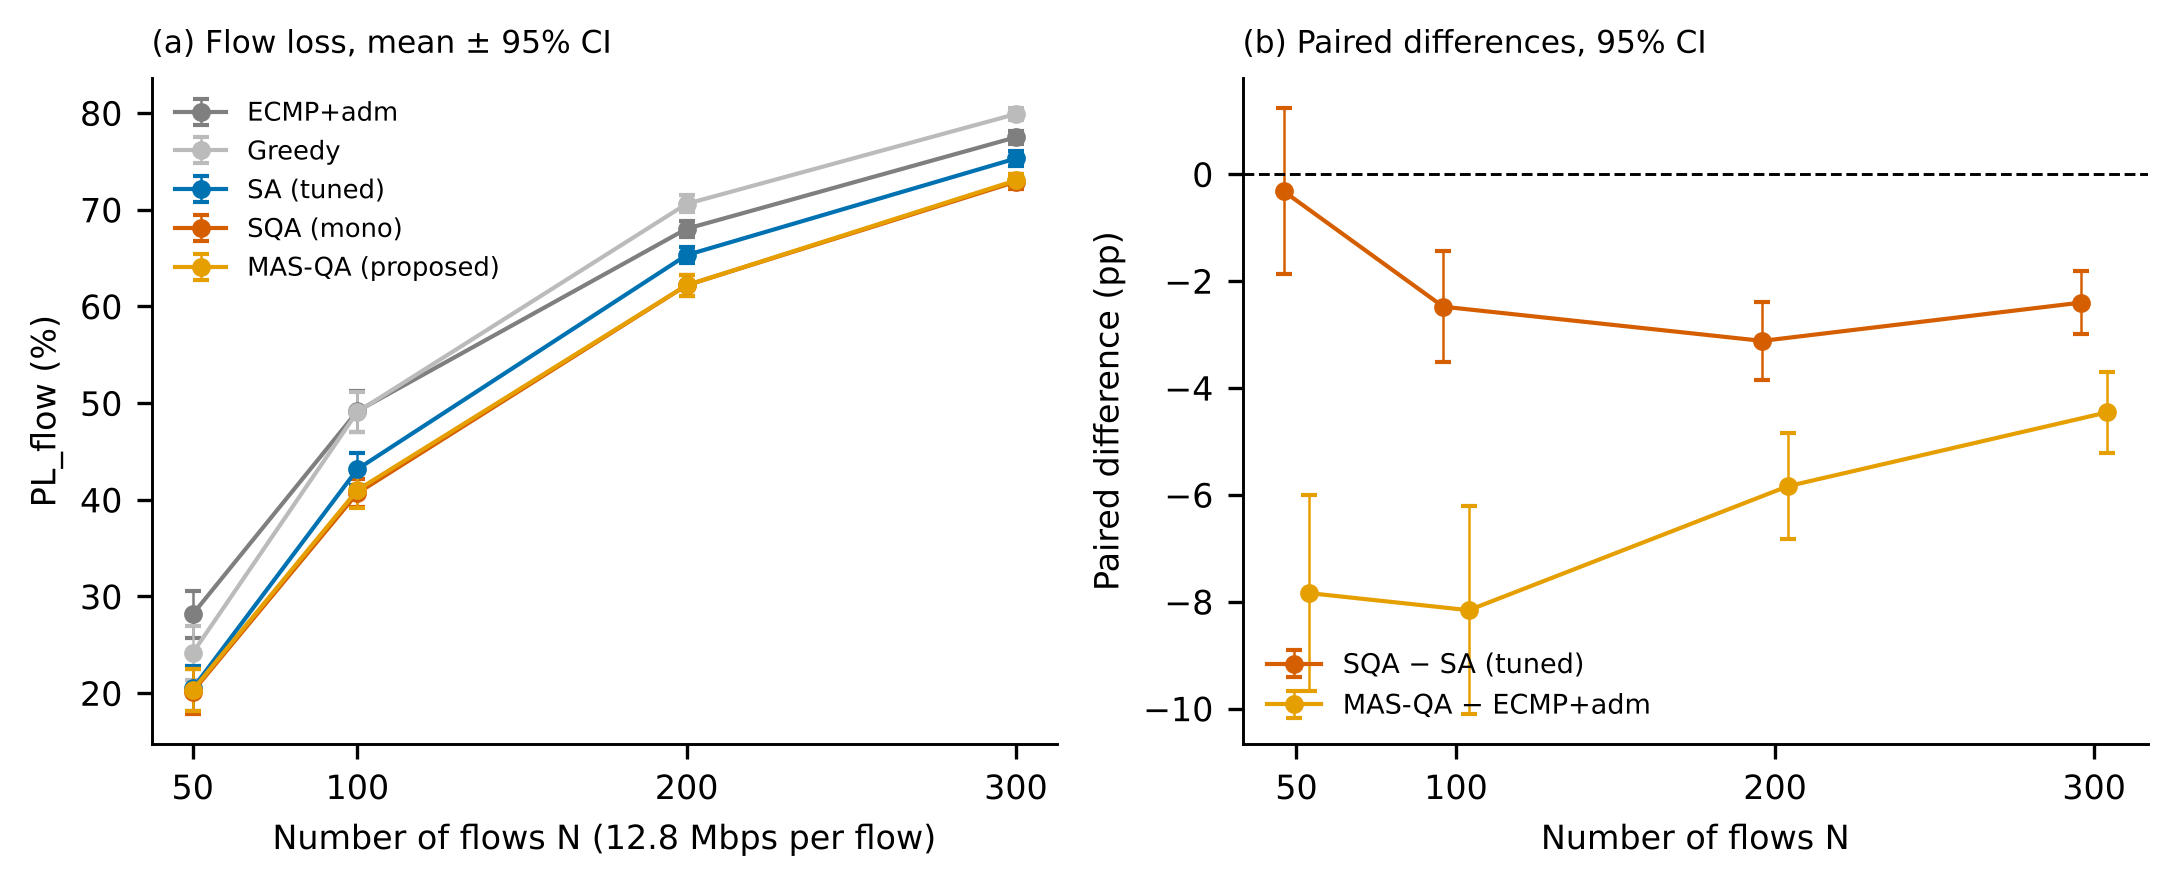

In [18]:
display(Image(filename=os.path.join(A.FIG, 'fig10_scale.png'), width=760))

Figure 10. Scale study with per-flow demand fixed at 12.8 Mbps, seeds 42–66 (25 seeds per size; 24 for N = 300). (a) PL_flow, mean ± 95% CI. (b) Paired differences with 95% CI: SQA minus tuned SA, and MAS-QA minus ECMP+adm.

**Figure 10.** Scale study with per-flow demand fixed at 12.8 Mbps, seeds 42–66 (25 seeds per size; 24 for N = 300). (a) PL_flow, mean ± 95% CI. (b) Paired differences with 95% CI: SQA minus tuned SA, and MAS-QA minus ECMP+adm.

Figure 10 reproduces the scale study. Panel (a) shows that every method loses more flows as N grows, because the fabric is loaded more heavily at constant per-flow demand. From N = 100 onward the two SQA-based methods have the lowest loss, with tuned SA close behind, while Greedy is the highest at N = 200 and 300. At N = 50 the solver-based methods and Greedy are close to one another. Panel (b) shows the paired differences. Tuned SQA minus tuned SA is near zero at N = 50 and between about −2.4 and −3.1 pp at N = 100 to 300. MAS-QA minus ECMP+adm lies between about −4.5 and −8 pp across the four sizes.

The scale study matches the main protocol. The SQA advantage over tuned SA is not significant at 50 flows (−0.3 pp) and is significant at 100, 200 and 300 flows (−2.5, −3.1 and −2.4 pp; unadjusted p < 0.001 in each case, and still significant after Bonferroni correction over the seven primary settings; Table 4, Figure 10). The pipeline beats capacity-aware ECMP at every size, by 4.5 to 8.2 pp. The advantage over ECMP narrows as N grows (−8.2 pp at 100 flows, −4.5 pp at 300 flows), so the gain should not be extrapolated beyond the sizes tested.

### 4.6 Distance from the exact optimum on small instances (RQ3)

Table 9. Small instances: PL_flow and BWL (%), mean over 20 seeds.

**Table 9.** Small instances: PL_flow and BWL (%), mean over 20 seeds.

_Table as printed in the article:_

| N | Load r | Method | PL_flow | BWL |
|---|---|---|---|---|
| 8 | 0.8 | ECMP+adm | 1.25 | 6.51 |
| 8 | 0.8 | Greedy-only | 1.88 | 4.12 |
| 8 | 0.8 | SA (mono, tuned) | 1.88 | 4.12 |
| 8 | 0.8 | SQA (mono, tuned) | 1.25 | 6.51 |
| 8 | 0.8 | OPT-count | 1.25 | 6.51 |
| 8 | 0.8 | OPT-bw | 1.88 | 4.12 |
| 8 | 1.6 | ECMP+adm | 15.00 | 23.95 |
| 8 | 1.6 | Greedy-only | 8.12 | 15.04 |
| 8 | 1.6 | SA (mono, tuned) | 8.12 | 16.76 |
| 8 | 1.6 | SQA (mono, tuned) | 8.12 | 17.01 |
| 8 | 1.6 | OPT-count | 8.12 | 14.85 |
| 8 | 1.6 | OPT-bw | 8.75 | 13.54 |
| 12 | 0.8 | ECMP+adm | 0.83 | 5.24 |
| 12 | 0.8 | Greedy-only | 0.83 | 5.24 |
| 12 | 0.8 | SA (mono, tuned) | 0.83 | 5.24 |
| 12 | 0.8 | SQA (mono, tuned) | 0.83 | 5.24 |
| 12 | 0.8 | OPT-count | 0.83 | 5.24 |
| 12 | 0.8 | OPT-bw | 0.83 | 5.24 |
| 12 | 1.6 | ECMP+adm | 17.92 | 30.60 |
| 12 | 1.6 | Greedy-only | 14.58 | 26.61 |
| 12 | 1.6 | SA (mono, tuned) | 15.00 | 28.83 |
| 12 | 1.6 | SQA (mono, tuned) | 14.17 | 28.49 |
| 12 | 1.6 | OPT-count | 14.17 | 27.68 |
| 12 | 1.6 | OPT-bw | 15.42 | 24.28 |

In [19]:
print('Table 9: recomputed from data/')
A.table9(sm)

Table 9: recomputed from data/


PL_flow    BWL
N  ratio method                            
8  0.8   ECMP+adm               1.25   6.51
         Greedy-only            1.88   4.12
         MAS-QA                 1.25   6.51
         OPT-bw                 1.88   4.12
         OPT-count              1.25   6.51
         SA-mono-mt+repair      1.88   4.12
         SQA-mono-v2+repair     1.25   6.51
   1.6   ECMP+adm              15.00  23.95
         Greedy-only            8.12  15.04
         MAS-QA                 8.12  15.65
         OPT-bw                 8.75  13.54
         OPT-count              8.12  14.85
         SA-mono-mt+repair      8.12  16.76
         SQA-mono-v2+repair     8.12  17.01
12 0.8   ECMP+adm               0.83   5.24
         Greedy-only            0.83   5.24
         MAS-QA                 0.83   5.24
         OPT-bw                 0.83   5.24
         OPT-count              0.83   5.24
         SA-mono-mt+repair      0.83   5.24
         SQA-mono-v2+repair     0.83   5.24
   1.6   ECMP+adm              17.92  30.60
         Greedy-only           14.58  26.61
         MAS-QA                15.00  27.48
         OPT-bw                15.42  24.28
         OPT-count             14.17  27.68
         SA-mono-mt+repair     15.00  28.83
         SQA-mono-v2+repair    14.17  28.49

Table 9 compares the heuristics with the exact optima (Figure 11). Each gap in Figure 11 is the per-seed difference from the count optimum, averaged over 20 seeds. A mean gap of 0.62 pp at N = 8 therefore corresponds to one seed in which one flow was lost, and 0.42 pp or 0.83 pp at N = 12 to one or two such seeds. At r = 0.8, MAS-QA and tuned SQA reach the count optimum at both sizes. Greedy and tuned SA each miss it on one seed at N = 8 (0.62 pp). At N = 12 every method, including ECMP+adm, reaches the optimum. At r = 1.6, ECMP+adm is 6.88 pp (N = 8) and 3.75 pp (N = 12) above the optimum. At N = 8 all other heuristics reach the optimum on every seed. At N = 12, tuned SQA is the only heuristic that reaches the optimum on all 20 seeds; Greedy misses on one seed, and tuned SA and MAS-QA each miss on two. Tuned SQA missed the count optimum on none of the 80 instances. These are means over 20 seeds, differences of one or two seeds, and no significance test was run, so they support an ordering of medians only. The instances are small and the demand rule is a simple scaling (Section 3.9), so the results do not establish optimality at realistic scale.

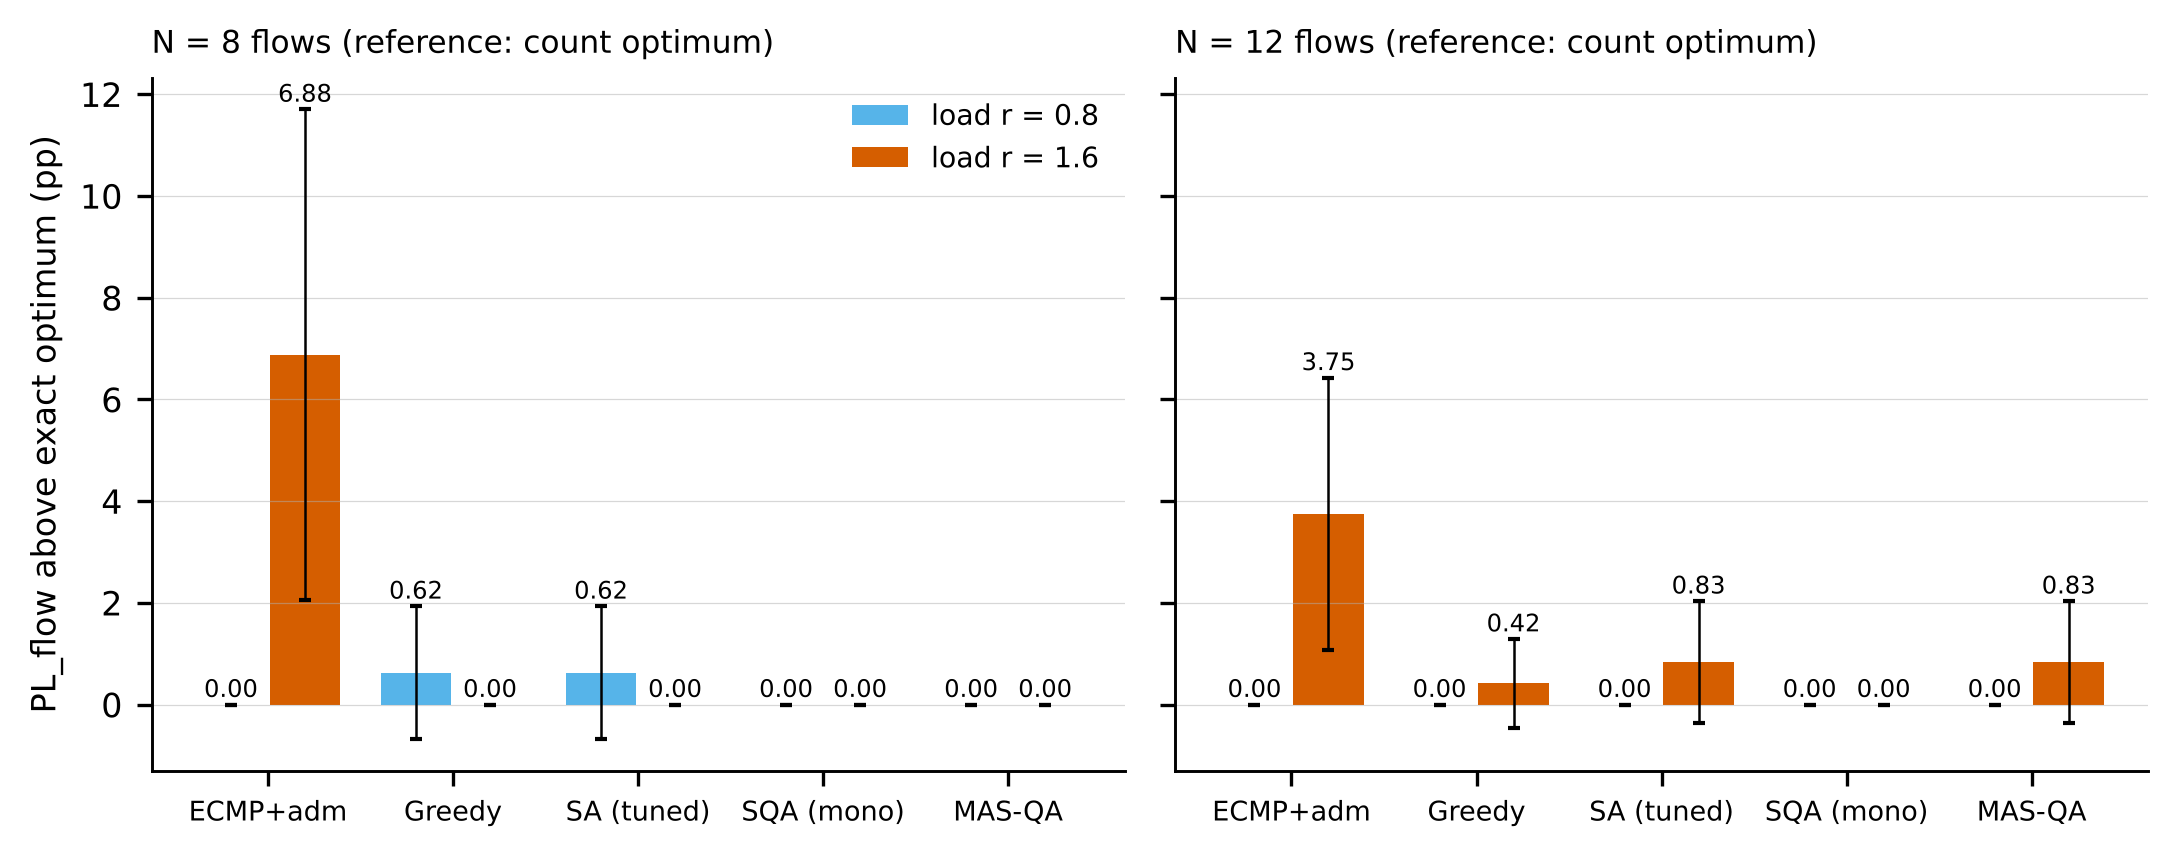

In [20]:
display(Image(filename=os.path.join(A.FIG, 'fig11_small_instances.png'), width=760))

Figure 11. Small instances against the exact MILP optimum (count objective), with total demand D_tot = r · 12.8 · N Mbps. Bars show the mean per-seed gap in PL_flow above the optimum for load ratios r = 0.8 and r = 1.6 (N = 8 and N = 12), for ECMP+adm, Greedy, tuned SA, tuned SQA (monolithic) and MAS-QA. Error bars are 95% CIs over 20 seeds. Labels give the mean gap in pp.

**Figure 11.** Small instances against the exact MILP optimum (count objective), with total demand D_tot = r · 12.8 · N Mbps. Bars show the mean per-seed gap in PL_flow above the optimum for load ratios r = 0.8 and r = 1.6 (N = 8 and N = 12), for ECMP+adm, Greedy, tuned SA, tuned SQA (monolithic) and MAS-QA. Error bars are 95% CIs over 20 seeds. Labels give the mean gap in pp.

Figure 11 shows the same gaps per seed. At r = 0.8, the only non-zero bars are for Greedy and tuned SA at N = 8, and ECMP+adm has no gap at either size. At r = 1.6, ECMP+adm lies far above the optimum at both sizes, and the other heuristics lie between 0 and 0.83 pp. The 95% intervals over 20 seeds include zero for every bar except ECMP+adm at r = 1.6, so the differences among the heuristics are within sampling noise.

### 4.7 Timing

Timing is reported only as a limitation. In our two-core container, the pod stage with two worker processes was not faster than sequential execution, and the cause was not identified. The coordinator time was not recorded correctly in the final runs and is not reported. The budgets of Section 3.5 are defined in spin updates, not in wall-clock time.

### 4.8 Sensitivity to the SA schedule

The SA schedule changes the result: the default schedule is 0.3 pp (S2) and 2.0 pp (S3) worse than the tuned schedule with repair (Table 2), so the choice of comparator matters at the level of the claimed effect. The objective weights were fixed before the experiments and were not tuned; the solver comparison uses the same baseline weights for both solvers. Their sensitivity is not evaluated here (Section 4.9).

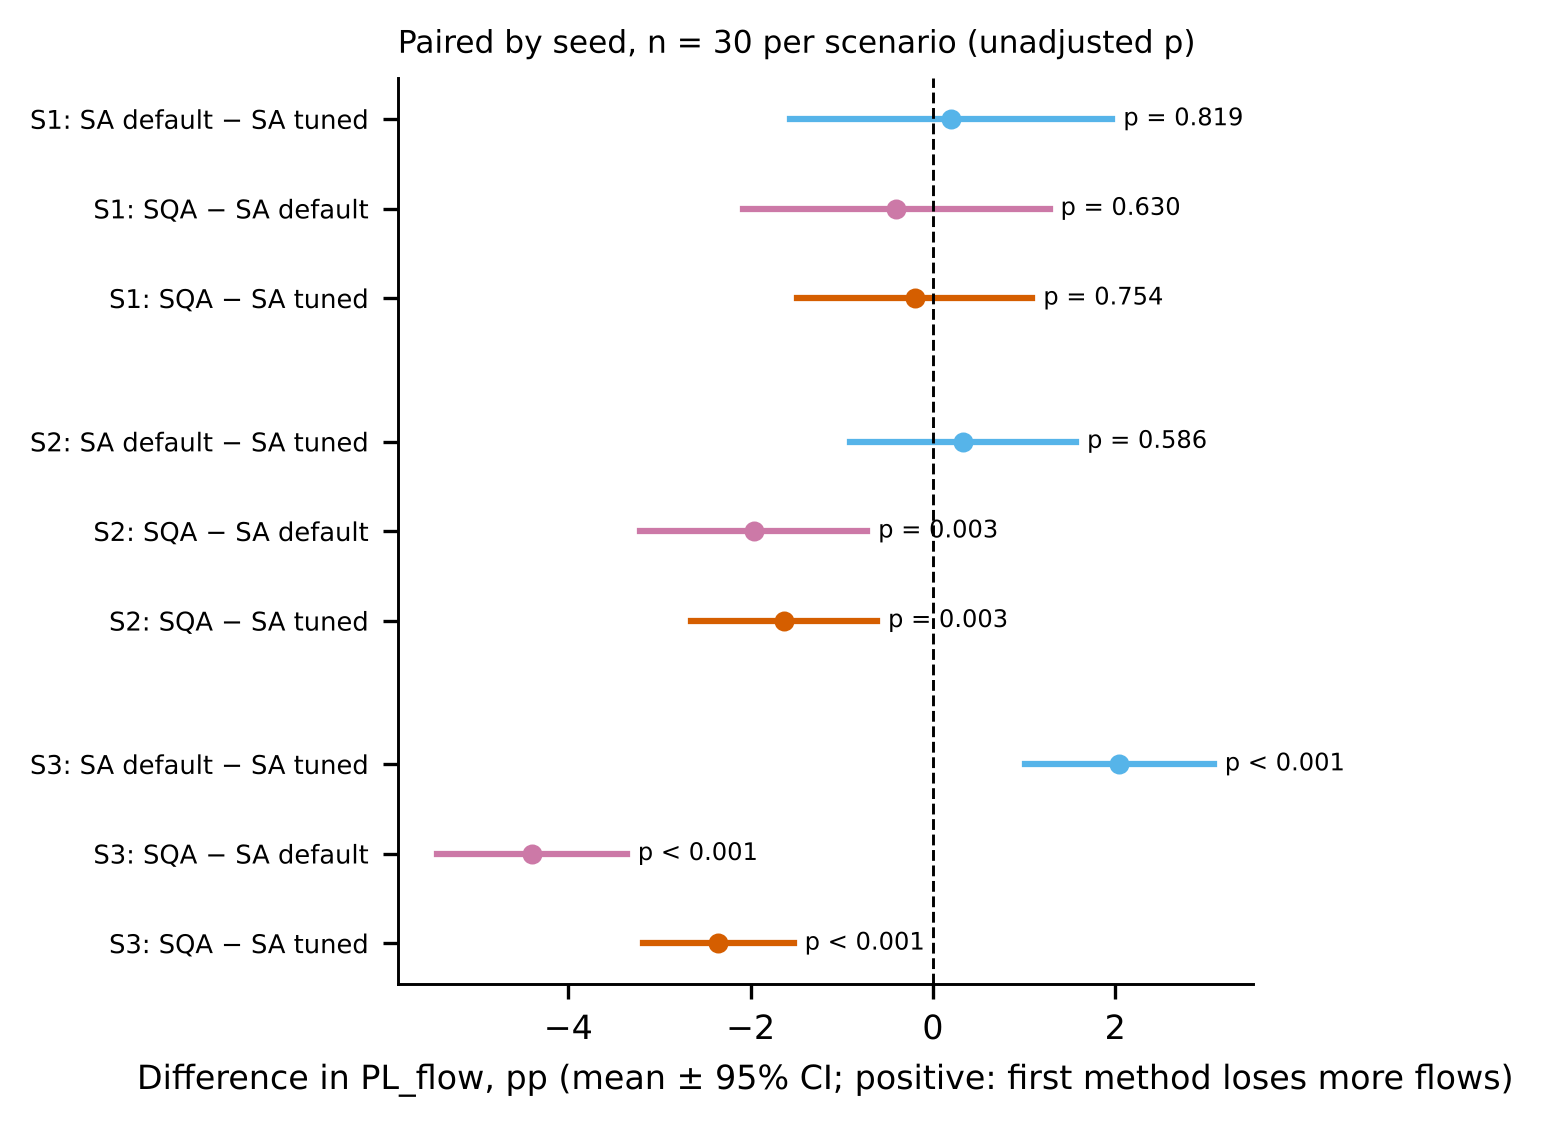

In [21]:
display(Image(filename=os.path.join(A.FIG, 'fig12_sa_schedule.png'), width=760))

Figure 12. Effect of the SA schedule on the SQA headline. Paired differences in PL_flow (pp, mean with 95% confidence interval; n = 30 seeds per scenario) for three contrasts: SA with the default schedule minus SA with the tuned schedule; SQA minus SA with the default schedule; and SQA minus SA with the tuned schedule. Unadjusted paired t-test p values are shown. Positive values mean that the first method loses more flows.

**Figure 12.** Effect of the SA schedule on the SQA headline. Paired differences in PL_flow (pp, mean with 95% confidence interval; n = 30 seeds per scenario) for three contrasts: SA with the default schedule minus SA with the tuned schedule; SQA minus SA with the default schedule; and SQA minus SA with the tuned schedule. Unadjusted paired t-test p values are shown. Positive values mean that the first method loses more flows.

Figure 12 separates the three contrasts discussed in this section. The default SA schedule is 0.2 pp worse than the tuned schedule in S1, 0.3 pp in S2 and 2.0 pp in S3, and only the S3 difference is significant. Measured against the default schedule, the SQA advantage is 2.0 pp in S2 and 4.4 pp in S3. Measured against the tuned schedule, it is 1.6 pp and 2.4 pp, as reported in Section 4.2. The default-schedule comparison would therefore overstate the SQA gain by 0.3 pp in S2 and 2.0 pp in S3, which is the sensitivity described above and in Section 4.10. The S1 contrasts are not significant under either schedule.

### 4.9 Limitations of the evidence

Surrogate metrics: PL_flow and BWL count whole flows as lost; latency is propagation delay only. Queueing, bursts, transport feedback and rule-installation cost are not modelled.

No emulation: Mininet, Ryu or P4 experiments were not run.

Baselines: learning-based and published quantum-annealing methods were not reproduced; no comparison with them is made.

Tuning: SA was tuned on four candidates and SQA on a small grid, both on validation seeds. Stronger tuning of either solver could change the gap.

Budget: the pipeline uses about 1/6 of the monolithic annealing work at the tuned settings. The equal-work control uses the initial solver settings only, so the equal-work trade-off has not been measured with tuned settings.

Scale: at most 16 hosts in the main study and 300 flows in the scale study; demand is static.

Compute: budgets are matched in spin updates, not measured time; wall-clock comparisons were not validated.

Weights: the objective weights were fixed before the experiments and not tuned; their sensitivity is not evaluated.

Exact reference: small instances (N ≤ 12) with a simple demand scaling (Section 3.9).

Table 10 sets out each limitation, what it means for the claims, and how the manuscript handles it.

Table 10. Limitations of the evidence, their effect on the claims, and how each is handled.

**Table 10.** Limitations of the evidence, their effect on the claims, and how each is handled.

| Limitation | Effect on the claims | Handling in this manuscript |
|---|---|---|
| Surrogate metrics (PL_flow, BWL); no queueing, bursts or transport feedback | Loss counts whole flows; an admitted flow may still fail in practice. | Defined in Section 3.7. Latency is not used to rank methods (Section 4.4). |
| No emulation (Mininet, Ryu or P4) | Controller behaviour and rule-installation delay are untested. | Stated here; future work items (iii) and (iv). |
| Learning-based and published quantum-annealing baselines not reproduced | No ranking of this pipeline against them. | Stated in Sections 2.1 and 2.2 and Table 1; future work item (i). |
| Tuning of each solver on a limited grid or candidate set | Stronger tuning of either solver could change the gap. | Both solvers tuned on validation seeds; default SA reported as a second comparator (Section 4.8). |
| Budget: pipeline uses about one sixth of the monolithic work; equal-work control uses initial settings only | The equal-work trade-off with tuned settings is not measured. | Stated in Section 4.2; future work item (ii). |
| Scale: at most 16 hosts and 300 flows; static demand | Results are not extrapolated to larger fabrics or time-varying traffic. | Stated in Section 4.5; future work item (iv). |
| Compute budgets matched in spin updates, not measured time | Wall-clock comparisons are not validated. | Timing reported only as a limitation (Section 4.7); future work item (v). |
| Objective weights fixed and not tuned | The solver ranking may depend on the weights; this is not tested. | Stated in Sections 3.3 and 4.9. |
| Exact reference on small instances (N ≤ 12) with a simple demand scaling | Optimality statements are limited to small instances. | Stated in Sections 3.9 and 4.6; future work item (vii). |

### 4.10 Interpretation for the research questions

RQ1 is answered conditionally. Under matched sweep budgets, with both solvers tuned on validation seeds and one shared repair rule, tuned SQA loses 1.6 pp (S2) and 2.4 pp (S3) fewer flows than tuned SA, and 2.4 to 3.1 pp fewer at N = 100, 200 and 300 (Sections 4.2 and 4.5). In S1 and at N = 50 the difference is not significant. These are gaps of a few percentage points, measured in one topology with one traffic model. They do not establish a general advantage of quantum annealing over classical annealing, and the claim should be read only within the settings tested.

The size of the effect is of the same order as the sensitivity to the comparator. The default SA schedule is 0.3 to 2.0 pp worse than the tuned schedule (Section 4.8). A comparison against default SA would therefore overstate the SQA gain by a similar amount. The claim depends on tuning both solvers on the same validation protocol, and we report it that way.

The advantage also depends on how the annealing budget is allocated. At equal total annealing work and with initial solver settings, the monolithic solver is 2.1 pp better than the pod pipeline in S1, and the difference is not significant in S2 and S3 (Section 4.2). A single budget therefore cannot rank the two configurations. Any reader who compares a pipeline with a monolithic solver should state the budget used for each.

The pod pipeline is best read as a device for reducing work, not for improving quality. At the tuned budget it reaches the monolithic SQA flow loss within 0.6 pp, not significantly, while using about one sixth of the annealing work per solve (Section 4.2). Iterating the pods with background loads gives no significant gain, and the share of variables that change does not settle within five rounds (Figure 6). The simple source-pod decomposition with b = 0 is therefore the version we would recommend.

Repair has a larger effect than the choice of solver (RQ2). Without repair, between 53% and 96% of the flows are lost, because an overloaded arc drops every flow that crosses it. Given repair, the solver contributes 3.5 to 8.4 pp over the greedy coordinator (Section 4.3). The SQA–SA gap of 1.6 to 3.1 pp is smaller than the effect of the feasibility step. A gain over a classical method that lacks an equivalent repair step may therefore reflect the repair rather than the annealer. Priority ordering does not give strong EF protection under any solver-based pipeline (Table 6, Figure 8), so it should not be presented as a QoS guarantee.

The small-instance study (RQ3) shows that the heuristics lie at or near the exact optimum at N = 8 and 12 under the demand scaling of Section 3.9. Tuned SQA missed the count optimum on none of the 80 instances. The other heuristics missed it on one or two seeds in the settings where they missed at all. These differences are one or two seeds out of 20 and are not tested for significance, so they support an ordering of medians only. They do not show how the gap behaves at the sizes of Section 4.5.

The largest effect in the study is the gap between the pipeline and ECMP+adm, which is 6.9 to 7.7 pp in the main scenarios and 4.5 to 8.2 pp in the scale study. It is the least informative effect for the choice of solver, because it compares an optimizer with a rule that does not optimize. We therefore do not use it to rank SQA against SA.

Three claims are outside what the study supports. First, both solvers are classical simulations: SQA is a path-integral Monte Carlo method run on a CPU, not a quantum device, and no hardware advantage is claimed. Second, wall-clock timing was not validated (Section 4.7). Third, the learning-based and published quantum-annealing routing methods were not reproduced, so the study cannot rank this pipeline against them.

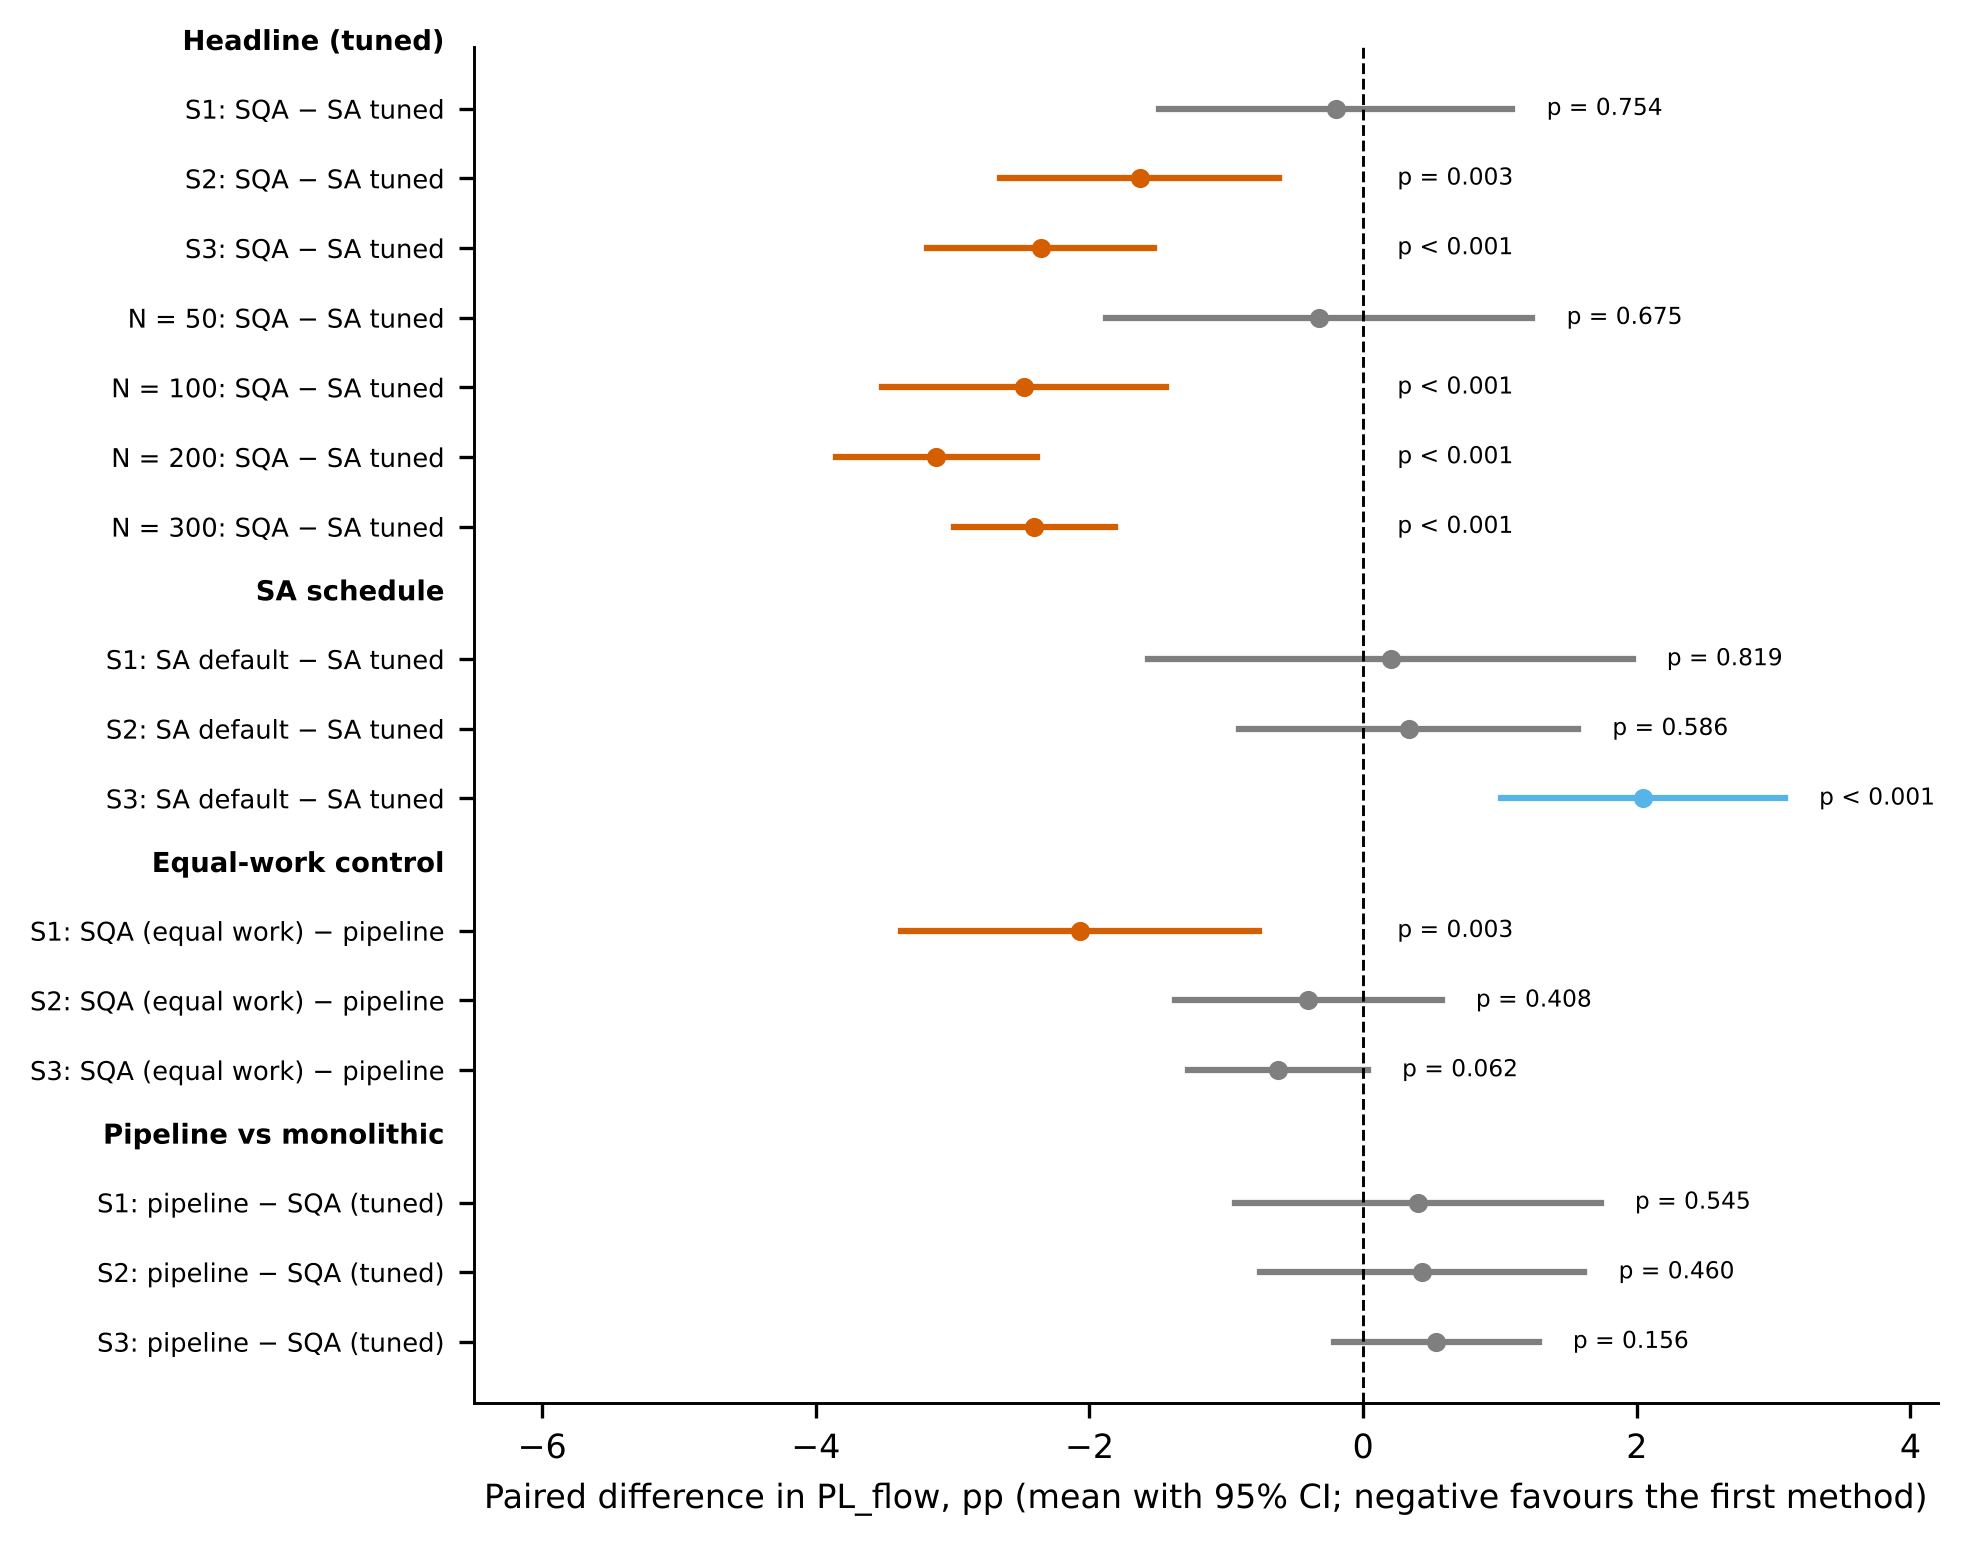

In [22]:
display(Image(filename=os.path.join(A.FIG, 'fig13_summary_contrasts.png'), width=760))

Figure 13. Summary of the paired contrasts discussed in Section 4.10: mean difference in PL_flow with 95% confidence interval (pp; negative values favour the first-named method). Headline rows compare tuned SQA with tuned SA in the main scenarios and at N = 50–300. SA schedule rows compare the default and tuned SA schedules. Equal-work rows compare monolithic SQA at equal annealing work with the pod pipeline, using initial settings. Pipeline rows compare the pipeline with tuned monolithic SQA at the tuned budget. Orange: interval below zero; blue: interval above zero; grey: interval includes zero. p values are unadjusted paired t-test values; n = 24–30 seeds per row.

**Figure 13.** Summary of the paired contrasts discussed in Section 4.10: mean difference in PL_flow with 95% confidence interval (pp; negative values favour the first-named method). Headline rows compare tuned SQA with tuned SA in the main scenarios and at N = 50–300. SA schedule rows compare the default and tuned SA schedules. Equal-work rows compare monolithic SQA at equal annealing work with the pod pipeline, using initial settings. Pipeline rows compare the pipeline with tuned monolithic SQA at the tuned budget. Orange: interval below zero; blue: interval above zero; grey: interval includes zero. p values are unadjusted paired t-test values; n = 24–30 seeds per row.

Figure 13 places the contrasts of this section on one scale. The headline rows with intervals below zero are S2, S3 and N = 100, 200 and 300, and they all favour SQA; these are the rows that survive the seven-setting correction in Section 4.2. The SA schedule row that is significant is S3 only, and it shows the default schedule as the weaker comparator. The equal-work control is significant only in S1, where the monolithic solver is better. The pipeline rows lie between 0.4 and 0.5 pp above tuned monolithic SQA, and all three intervals include zero. This is consistent with the statement in Section 4.2 that the pipeline is within 0.6 pp of monolithic SQA at the tuned budget, while using about one sixth of the annealing work.

## 5. Conclusions and Future Work

We compared simulated quantum annealing and simulated annealing for SDN flow admission under matched sweep budgets, with validation-selected settings for both solvers, one shared admission and repair rule, and seeds disjoint from the tuning seeds. At 100 or more flows, tuned SQA loses 1.6 to 3.1 pp fewer flows than tuned SA; at 50 flows the difference is not significant. A pod decomposition reaches the monolithic SQA flow loss within 0.6 pp at the tuned budget, with about one-sixth of its annealing work; at equal work with initial settings, it is 2.1 pp worse at 50 flows. Iterating the pods with background loads gives no significant gain. Feasibility repair is necessary for every solver: without it, most flows are lost. Given repair, the solver adds 3.5 to 8.4 pp over a greedy coordinator, and the full pipeline reduces lost flows by 4.5 to 8.2 pp relative to capacity-aware ECMP. The study does not claim a multi-agent architecture or a sub-second control loop, because neither is evaluated.

Future work should, in order: (i) reproduce published learning-based and quantum-annealing routing methods under the same admission, repair and validation protocol; (ii) repeat the equal-work comparison with tuned settings for both the monolithic and pod solvers, and validate the SA schedule on fresh seeds; (iii) connect the surrogate metrics to delivered traffic through emulation (Mininet with Ryu or ONOS) and a queueing model with per-class tail latency; (iv) study larger networks, time-varying demand and rule-installation delay; (v) measure wall-clock time on a multi-core host with instrumentation that records the coordinator time; (vi) add a priority-aware objective term to address the weak EF protection; and (vii) test the small-instance results under a capacity-based demand rule and on larger exact instances.

## Data and code availability

The simulation code (MIT licence), the Colab notebook, and the per-run simulation data (CC BY 4.0) are being prepared for public release. Repository and dataset identifiers will be inserted here: [GitHub URL to be inserted] and [Zenodo DOI to be inserted]. The dataset includes the per-seed results behind every table and figure, the validation and tuning results, and the scripts that generate them.

## Declarations

Funding: [to be completed]. Conflicts of interest: [to be completed]. Author contributions: [to be completed]. Ethical approval: not applicable (simulation study without human participants).

## References

[1] Hopps C. Analysis of an Equal-Cost Multi-Path Algorithm. RFC 2992, 2000.

[2] Al-Fares M., Loukissas A., Vahdat A. A Scalable, Commodity Data Center Network Architecture. SIGCOMM, 2008.

[3] Kreutz D., Ramos F.M.V., Veríssimo P.E., Rothenberg C.E., Azodolmolky S., Uhlig S. Software-Defined Networking: A Comprehensive Survey. Proc. IEEE, 103(1), 2015.

[4] Nunes B.A.A., Mendonca M., Nguyen X.-N., Obraczka K., Turletti T. A Survey of Software-Defined Networking. IEEE Commun. Surveys Tuts., 16(3), 2014.

[5] Al-Fares M., Radhakrishnan S., Raghavan B., Huang N., Vahdat A. Hedera: Dynamic Flow Scheduling for Data Center Networks. NSDI, 2010.

[6] Glover F., Kochenberger G., Du Y. A tutorial on formulating and using QUBO models. arXiv:1811.11538, 2018.

[7] Lucas A. Ising formulations of many NP problems. Front. Phys., 2, 5, 2014.

[8] Kadowaki T., Nishimori H. Quantum annealing in the transverse Ising model. Phys. Rev. E, 58, 5355, 1998.

[9] Martoňák R., Santoro G.E., Tosatti E. Quantum annealing by the path-integral Monte Carlo: application to the Ising model. Phys. Rev. B, 66, 094203, 2002.

[10] Kirkpatrick S., Gelatt C.D., Vecchi M.P. Optimization by simulated annealing. Science, 220, 1983.

[11] M. Mallegowda, Narasimha Murthy Madiwala Sathynarayna Rao, Atur Venkateshmurthy Krishna Mohan, Kannughatta Narasimhamurthy Shreenath, Thirthe Gowda Mallinathapura Thimmegowda. Temporal Graph Neural Network with Rollback-aware Message Passing and Soft Actor Critic Based Load Balancing in Cloud Computing. Int. J. Intell. Eng. Syst., 19(5), p. 370, 2026. doi:10.22266/ijies2026.0531.22

[12] Suganya Balan, Padmapriya Ramakrishnan. An Enhanced Hybrid Task Scheduling with Load Balancing in Cloud with Prediction of Future Resource Demands. Int. J. Intell. Eng. Syst., 19(3), p. 306, 2026. doi:10.22266/ijies2026.0331.19

[13] Mohammed Ibrahim Kareem, Ali Z.K. Matloob, Harith Abbas Kadhim, Ali Kadhum M. Al-Qurabat. Bio-inspired Waggle Dance-driven Transformer for Adaptive Intrusion Detection in Software-defined Networks. Int. J. Intell. Eng. Syst., 19(4), p. 1051, 2026. doi:10.22266/ijies2026.0430.60

[14] Xiang M., Chen M., Wang D., Luo Z. Deep Reinforcement Learning-based load balancing strategy for multiple controllers in SDN. e-Prime: Advances in Electrical Engineering, Electronics and Energy, 2, 100038, 2022. doi:10.1016/j.prime.2022.100038

[15] Witt A., Kim J., Körber C., Luu T. ILP-based resource optimization realized by quantum annealing for optical wide-area communication networks. Frontiers in Computer Science, 6, 1356983, 2024. doi:10.3389/fcomp.2024.1356983

[16] Zahraa A. Jaaz, Farah Saad Al-Mukhtar, Zainab Haider Ameen, Mohd Ezanee Bin Rusli, Maamoun Ahmed. Design of a Hybrid Routing and Congestion Control Algorithm Used for Decreasing Latency and Packet Loss in Next-generation Wireless Networks. Int. J. Intell. Eng. Syst., 19(4), p. 930, 2026. doi:10.22266/ijies2026.0430.53

[17] S M K M Abbas Ahmad, Mohammad Junaid Khan, Dustakar Surendra Rao. Secure Routing in Ad Hoc Networks through Federated GNN Trust Aggregation and Topology-aware Flow Analysis. Int. J. Intell. Eng. Syst., 19(2), p. 511, 2026. doi:10.22266/ijies2026.0228.32

[18] Mohammed B. S Jaber, Omar Y. Shaaban. Deep Reinforcement Learning for Proactive Spectrum Defragmentation in Elastic Optical Networks. Int. J. Intell. Eng. Syst., 19(2), p. 297, 2026. doi:10.22266/ijies2026.0228.19

[19] Wisam Hasan Ali, Raad S. Alhumaima, Mohammed Khawwam Ahmed. Renewable Aware Power and Resource Optimization in ORAN: A Convex Formulation with Comparative Solver Analysis. Int. J. Intell. Eng. Syst., 19(4), p. 1004, 2026. doi:10.22266/ijies2026.0430.57

[20] Baraa Saad Abdulhakeem, Mustafa Maad Hamdi, Mohammed Shihab Hamad, Ahmed Adil Nafea. Hypergraph-based Reinforcement Learning for Interference-aware Resource Allocation in UAV-assisted VANETs. Int. J. Intell. Eng. Syst., 19(5), p. 573, 2026. doi:10.22266/ijies2026.0531.33

[21] Zakaria Benlalia, Mohammed El KAIM Billah, Toufik Mzili. HSRSO: A Diversity-adaptive Hybrid Harmony Search–Rat Swarm Optimization Algorithm for Efficient Cloud Task Scheduling. Int. J. Intell. Eng. Syst., 19(3), p. 1068, 2026. doi:10.22266/ijies2026.0331.63

[22] Rizki Muliono, Nukhe Andri Silviana, Yudi Daeng Polewangi, Andre Hasudungan Lubis. KRG-VRP: An Integrated Hybrid Machine Learning Framework Integrating K-Means++, Random Forest, and Genetic Algorithm for Capacitated Vehicle Routing Optimization. Int. J. Intell. Eng. Syst., 19(5), p. 143, 2026. doi:10.22266/ijies2026.0531.10

[23] Jain R., Chiu D.-M., Hawe W. A Quantitative Measure of Fairness and Discrimination for Resource Allocation in Shared Computer Systems. DEC-TR-301, 1984.

[24] Wilcoxon F. Individual comparisons by ranking methods. Biometrics Bulletin, 1(6), 1945.

[25] Dunn O.J. Multiple comparisons among means. JASA, 56, 1961.

[26] Virtanen P., et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. Nature Methods, 17, 2020 (milp; HiGHS).

[27] OpenJij Developers. OpenJij: Ising machine and simulated quantum annealing library. https://github.com/OpenJij/OpenJij

[28] Vert D., Willsch M., Yenilen B., Sirdey R., Louise S., Michielsen K. Benchmarking quantum annealing with maximum cardinality matching problems. Frontiers in Computer Science, 6, 1286057, 2024. doi:10.3389/fcomp.2024.1286057

[29] Tsai T.H., Chen Y.C., Nien C.F. Network Bandwidth Utilization Optimization with Quantum-Inspired Approach. SPIN, 13(4), 2340015, 2023. doi:10.1142/S2010324723400155

[VERIFY before submission: confirm Scopus indexing of [14], [15], [28], [29] and [11–13, 16–22] in the Scopus Sources list. Journal pages state Scopus indexing for IJIES (inass.org) and Frontiers in Computer Science (frontiersin.org); a third-party listing states it for e-Prime (Editage). DOIs and abstracts of [11–13, 16–22] were checked against the article PDFs.]

# Reproducibility checks

The cells below compare key numbers recomputed from `data/` with the values reported in the article. Each check prints OK when the recomputed value agrees with the reported value at the precision used in the text.

In [23]:
m_ = A.headline(m, sc).set_index('setting')
checks = {
  'Headline S2 (pp)': (round(m_.loc['S2', 'dbar'], 2), -1.63),
  'Headline S3 (pp)': (round(m_.loc['S3', 'dbar'], 2), -2.36),
  'Scale N=100 (pp)': (round(m_.loc['N=100', 'dbar'], 2), -2.48),
  'Scale N=200 (pp)': (round(m_.loc['N=200', 'dbar'], 2), -3.12),
  'Equal-work S1 (pp)': (round(A.equal_work(ea)['S1']['dbar'], 2), -2.07),
  'SA default - tuned S3 (pp)': (round(A.paired(A.ser(m, 'scenario', 'S3', A.SAD), A.ser(m, 'scenario', 'S3', A.SAT))['dbar'], 2), 2.04),
}
for k, (got, want) in checks.items():
    print(('OK  ' if abs(got - want) < 0.006 else 'DIFF'), k, 'recomputed', got, 'article', want)

OK   Headline S2 (pp) recomputed -1.63 article -1.63
OK   Headline S3 (pp) recomputed -2.36 article -2.36
OK   Scale N=100 (pp) recomputed -2.48 article -2.48
OK   Scale N=200 (pp) recomputed -3.12 article -3.12
OK   Equal-work S1 (pp) recomputed -2.07 article -2.07
OK   SA default - tuned S3 (pp) recomputed 2.04 article 2.04


## Data and code

- `data/` contains the per-run results used by every figure and table (see `data/README.md`).
- `code/masqa_lib.py`, `code/exp.py`: topology, traffic, QUBO, solvers, coordinator and experiment drivers (full runs take hours; see the repository README).
- `notebooks/` contains this notebook.

Licence: code under MIT; data under CC BY 4.0 (see `LICENSE` and the article's Data availability statement).